# Density profiles of TDP-43 condensates (equilibrium)

1. **Droplets**: TDP-43, enzyme, N- and C-terminal profiles; profiles split by number of pSer per chain
2. **Slabs**: phase diagram vs pSer, position of the enzymes (CALVADOS3 vs HPS-Urry), species arrangement

Every profile is saved and reloaded, so the figures can be re-run without the trajectories:
- condensate_structure profiles: `.npz` files in `analysis/friction01/condensate_structure/density_profiles/`
- slabs vs pSer: `density_profile_sim{s}_..._{bins,densities}.txt` in `analysis/friction01/pser_phase_diagram/slab_simulations/`

A profile is computed only if its file is missing; set `RECOMPUTE = True` in the setup cell to redo all of them.

The condensate_structure slabs have replicas (`sim1`, `sim2`, ... in `REPLICAS`): every replica is analysed from its
centred dump, saved as `{name}_sim{n}.npz`, recomputed when its dump has grown, and the replicas are averaged weighted
by their frames.
A system without replicas yet uses its single-run profile, with a warning.
pSer percentages are the fraction of the TDP-43 serines that are phosphorylated, read from the trajectories.


# Setup

In [26]:
import os
import sys

module_path = os.path.abspath('src')    # run the notebooks from the repository folder
if module_path not in sys.path:
    sys.path.insert(0, module_path)
from hpa.paths import SIM, AN, PL, INPUT_STATS, REPO, STYLES   # data locations (set HPA_DATA_ROOT to use another copy)

import numpy as np
from matplotlib import pyplot as plt
from scipy.optimize import curve_fit
import gsd.hoomd

import hpa.profiles as hpap
from hpa.plots import plot_radial_density_profiles_by_npSer
from hpa.stats import tanh_general

plt.style.use('default')
plt.style.use(STYLES + 'rates_plot.mplstyle')

In [33]:
path_struct = SIM + 'condensate_structure/'
path_struct_pl = PL + 'condensate_structure/'
path_pser = SIM + 'fixed_pser_uniform_slabs/'
path_pser_an = AN + 'fixed_pser_uniform_slabs/'
path_pser_pl = PL + 'fixed_pser_uniform_slabs/'
path_struct_an = AN + 'condensate_structure/'
prof_dir = path_struct_an + 'density_profiles/'    # saved profiles of the condensate_structure simulations
os.makedirs(prof_dir, exist_ok=True)

RECOMPUTE = False                    # True: recompute every saved profile

N_LCD = 154                          # beads of a TDP-43 LCD chain
ENZ_BEADS = {'ck1d': 292, 'pp3': 527}


def savefig(prefix, dpi=600):
    for ext in ('png', 'pdf'):
        plt.savefig(f'{prefix}.{ext}', dpi=dpi)


def cached(filename, compute):
    '''Arrays saved in filename (.npz); computed with compute() -> {name: array} and saved if missing or RECOMPUTE.'''
    if RECOMPUTE or not os.path.exists(filename):
        np.savez(filename, **compute())
    with np.load(filename) as z:
        return {k: z[k] for k in z.files}


def stairs_edges(centers):
    '''Bin edges for plt.stairs from equally spaced bin centers.'''
    w = centers[1] - centers[0]
    return np.append(centers - w / 2, centers[-1] + w / 2)


def pser_percent(gsd_file, n_tdp_beads):
    '''Percentage of the TDP-43 serines (first n_tdp_beads beads) that are phosphorylated.
    Read from the _end.gsd of the run (no reactions: same bead types as the trajectory, and in the Zenodo record).'''
    with gsd.hoomd.open(gsd_file.replace('_dump_centered.gsd', '_end.gsd'), 'r') as traj:
        frame = traj[0]
        names = np.asarray(frame.particles.types)[frame.particles.typeid[:n_tdp_beads]]
    n_sep, n_ser = np.sum(names == 'SEP'), np.sum(names == 'SER')
    return 100 * n_sep / (n_sep + n_ser)


def symmetric_half(rho):
    '''Average the two halves of a symmetric slab profile; returns the z > 0 half.'''
    half = len(rho) // 2
    return np.mean([rho[:half], rho[::-1][:half]], axis=0)[::-1]

# ---- replicas of the condensate_structure slabs -------------------------------------------------------------------
REPLICAS = [1, 2]                    # replicas of the condensate_structure slabs used together (sim1, sim2)


def dump_frames(path):
    '''Number of frames of a trajectory; None if it is not there or cannot be read yet (still being written).'''
    if not os.path.exists(path):
        return None
    try:
        with gsd.hoomd.open(path, 'r') as traj:
            return len(traj)
    except OSError:
        return None


def replica_cached(filename, dump, compute):
    '''Profiles of one replica saved in filename (.npz): computed with compute() from the trajectory dump if the file is
    missing, RECOMPUTE = True, or the dump has more frames than when the file was made (simulation still running then).
    Returns None if there is neither a file nor a readable trajectory.'''
    n = dump_frames(dump)
    if os.path.exists(filename) and not RECOMPUTE:
        with np.load(filename) as z:
            if n is None or int(z['dump_frames']) == n:
                return {k: z[k] for k in z.files}
    if n is None:
        return None
    out = compute()
    out['dump_frames'] = n
    np.savez(filename, **out)
    return out


def replica_average(name, dump_of, compute, average, folder=None, old_file=None):
    '''Profiles of the replicas REPLICAS, each saved as {folder}{name}_sim{r}.npz (see replica_cached), averaged over the
    replicas weighted by their frames ('frames_used'): the arrays named in `average`; the other entries are taken from
    the first replica. Without any replica the single-run file old_file (made before the replicas) is used.'''
    folder = prof_dir if folder is None else folder
    res = []
    for r in REPLICAS:
        out = replica_cached(f'{folder}{name}_sim{r}.npz', dump_of(r), lambda r=r: compute(dump_of(r)))
        if out is not None:
            res.append((r, out))
    if not res:
        if old_file is not None and os.path.exists(old_file):
            print(f'{name}: WARNING no replica (trajectories missing or not readable yet): single-run file used')
            with np.load(old_file) as z:
                return {k: z[k] for k in z.files}
        raise FileNotFoundError(f'{name}: no trajectories and no saved profiles')
    w = np.array([float(out['frames_used']) for _, out in res])
    combined = dict(res[0][1])
    for k in average:
        combined[k] = sum(wi * out[k] for wi, (_, out) in zip(w, res)) / w.sum()
    print(f'{name}: ' + ', '.join(f'sim{r} ({int(out["frames_used"])} frames)' for r, out in res))
    return combined

# 1. Droplets
## Enzymes and N-/C-terminal regions

In [5]:
# beads of the N-terminal (first 100) and C-terminal (last 54) residues of the 200 LCD chains
group_n_ter = np.array([i + N_LCD * nc for nc in range(200) for i in range(100)])
group_c_ter = np.array([100 + i + N_LCD * nc for nc in range(200) for i in range(54)])

drop_files = {
    ('ck1d', 0):    path_struct + 'sim_eq_200-tdp43-lcd_5-ck1d-open_CAL3_fr01/sim_eq_200-tdp43-lcd_5-com-ck1d-open_CAL3_fr01_dump_centered.gsd',
    ('ck1d', 1257): path_struct + 'sim_eq_200-tdp43-lcd_5-ck1d-open_CAL3_fr01/sim_eq_200-tdp43-lcd-1257pser_5-com-ck1d-open_CAL3_fr01_dump_centered.gsd',
    ('pp3', 0):     path_struct + 'sim_eq_200-tdp43-lcd_5-pp3_CAL3_fr01/sim_eq_200-tdp43-lcd_5-com-pp3_CAL3_fr01_dump_centered.gsd',
    ('pp3', 1257):  path_struct + 'sim_eq_200-tdp43-lcd_5-pp3_CAL3_fr01/sim_eq_200-tdp43-lcd-1257pser_5-com-pp3_CAL3_fr01_dump_centered.gsd',
}

# radial profiles of TDP-43 LCD, enzymes (5 copies), N-ter and C-ter for every droplet (saved, reloaded)
rho_drop = {}
for (enzyme, npser), f in drop_files.items():
    groups = {'tdp': np.arange(0, 30800), 'enz': np.arange(30800, 30800 + 5 * ENZ_BEADS[enzyme]),
              'nter': group_n_ter, 'cter': group_c_ter}

    def compute(f=f, groups=groups):
        out = {}
        for name, group in groups.items():
            out['r_centers'], out[name] = hpap.compute_radial_density_profile(f, r_max=50, group=group, therm=100)
        return out

    tag = f'-{npser}pser' if npser else ''
    prof = cached(prof_dir + f'radial_200-tdp43-lcd{tag}_5-{enzyme}_CAL3.npz', compute)
    for name in groups:
        rho_drop[enzyme, npser, name] = prof[name]
    r_centers = prof['r_centers']

x_stairs = stairs_edges(r_centers)                                   # 0, 0.5, ..., 50 nm
pct_drop = round(pser_percent(drop_files['pp3', 1257], 30800))       # 1257 pSer in 200 chains: 26%
print(f'droplets with 1257 pSer: {pct_drop}% of the serines phosphorylated')

Computing radial density: 100%|███████████████████████████████████| 2400/2400 [00:00<00:00, 3539.21it/s]

droplets with 1257 pSer: 26% of the serines phosphorylated


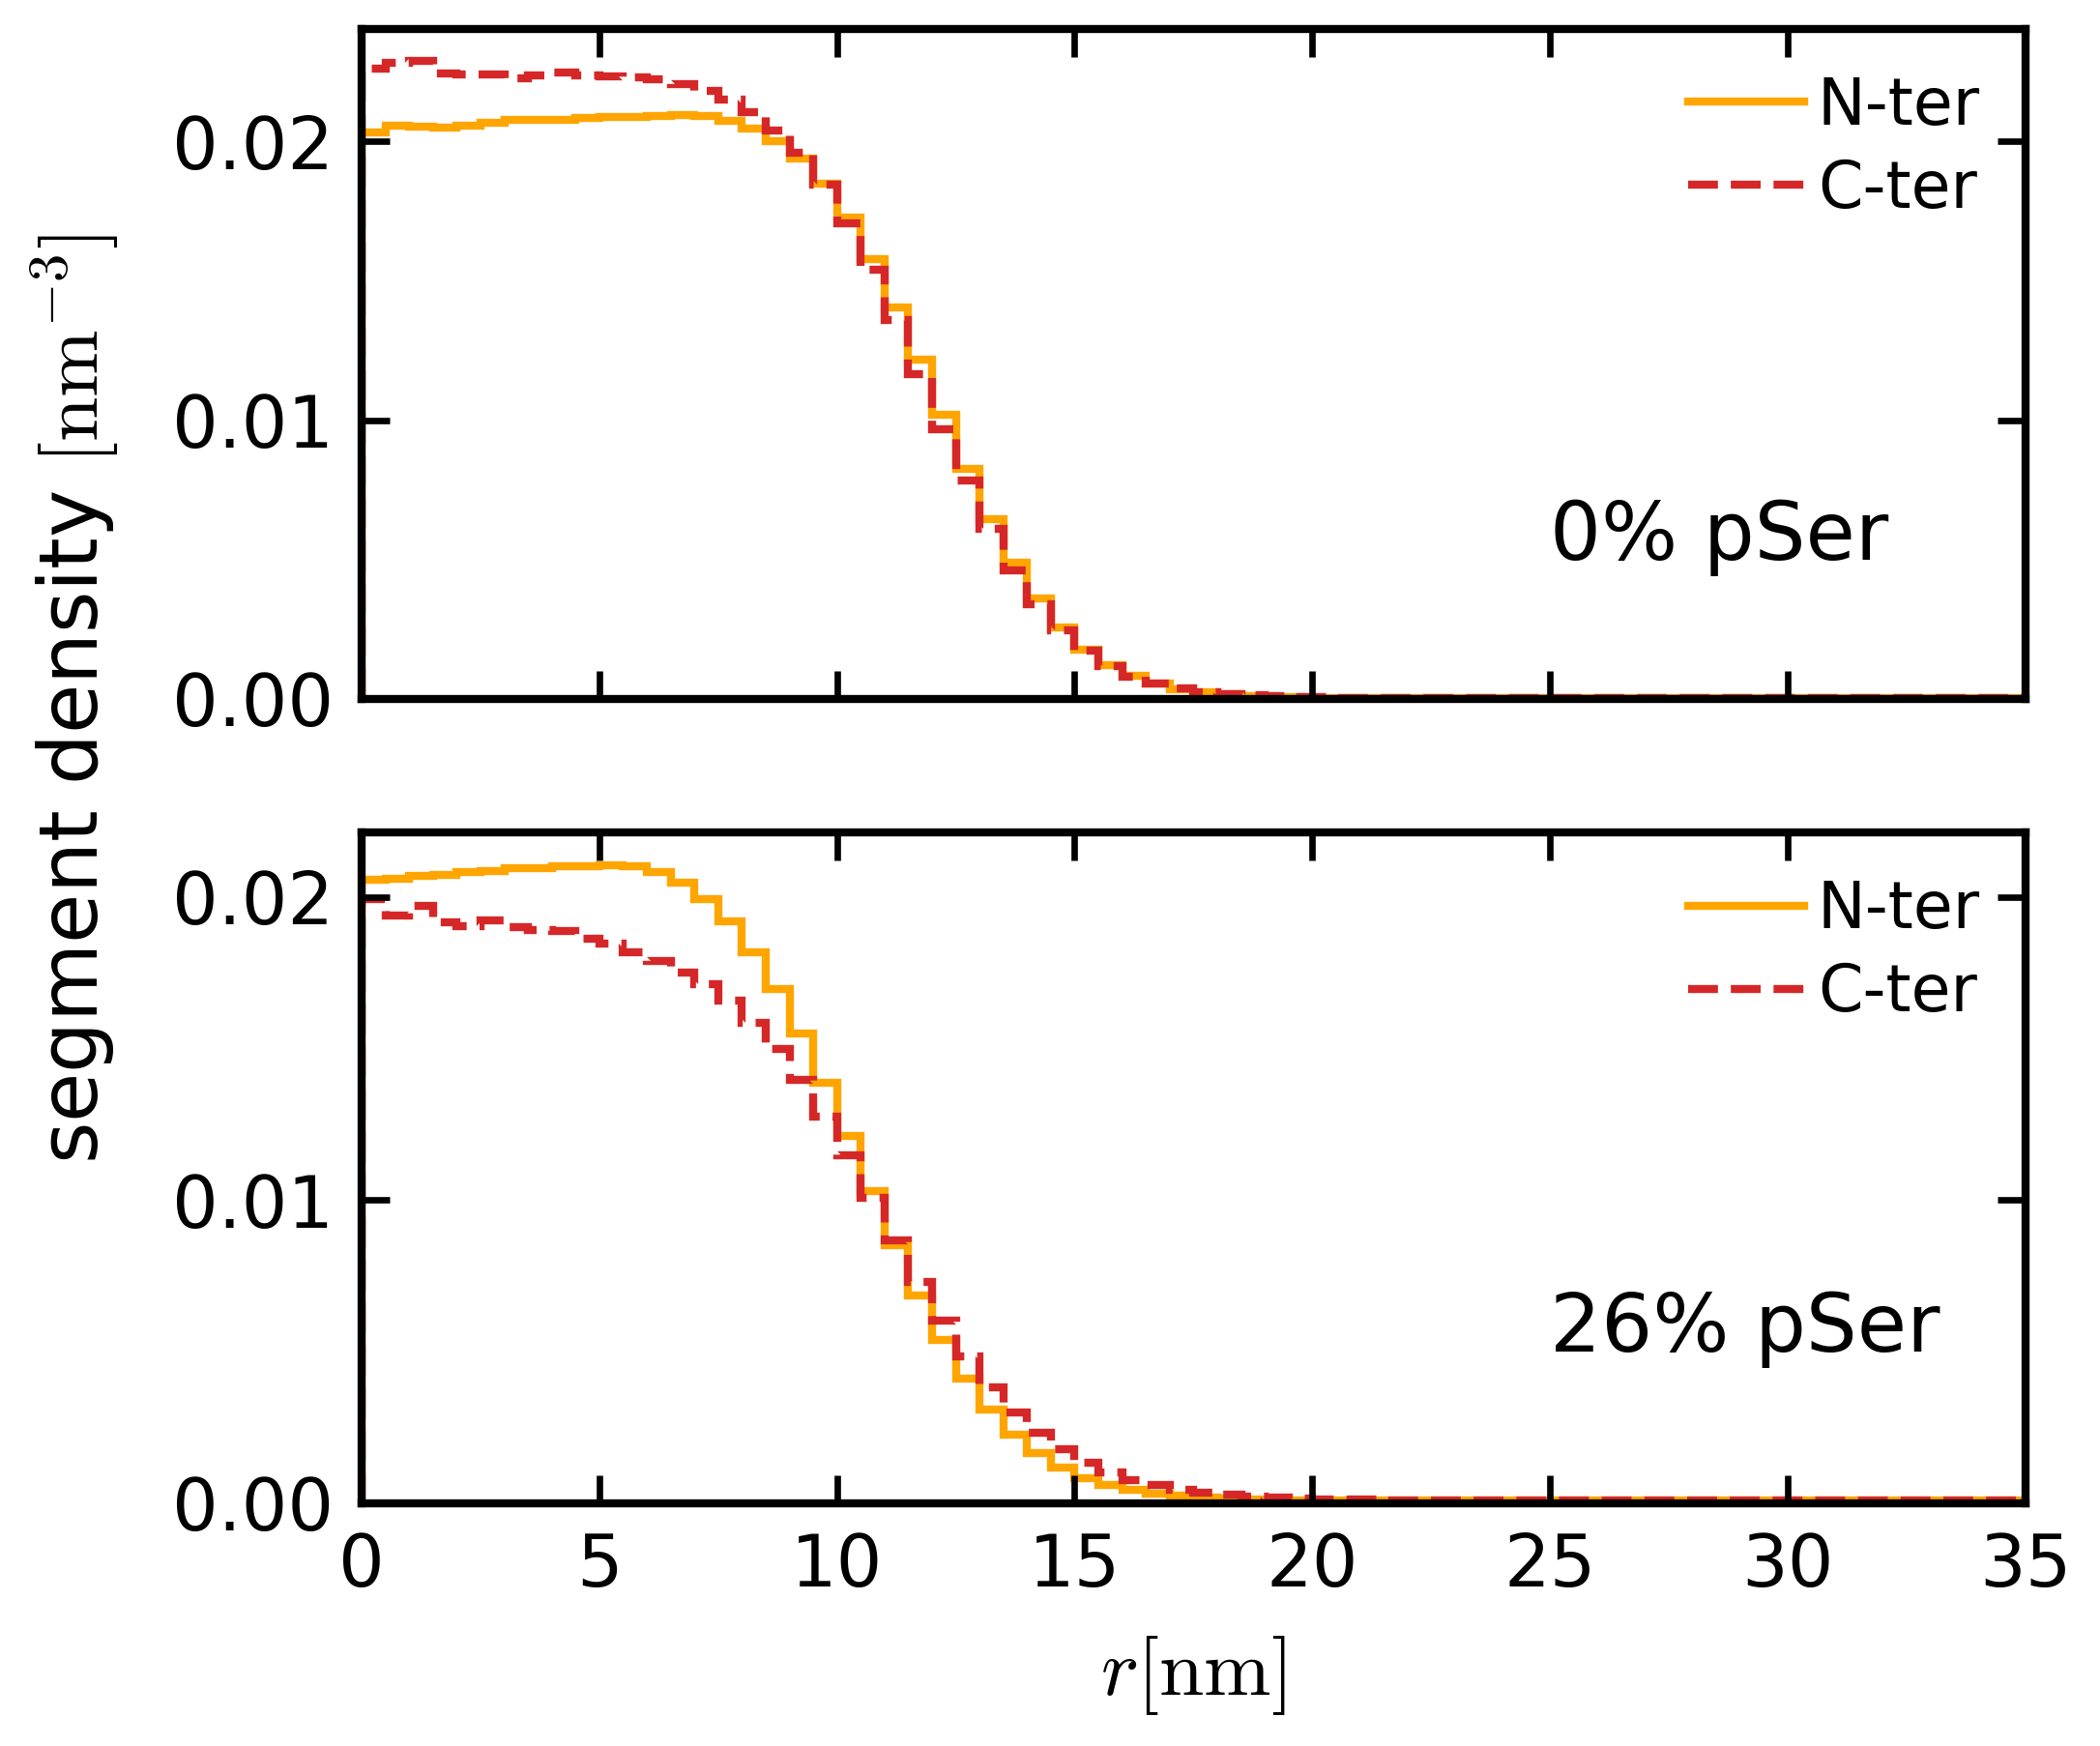

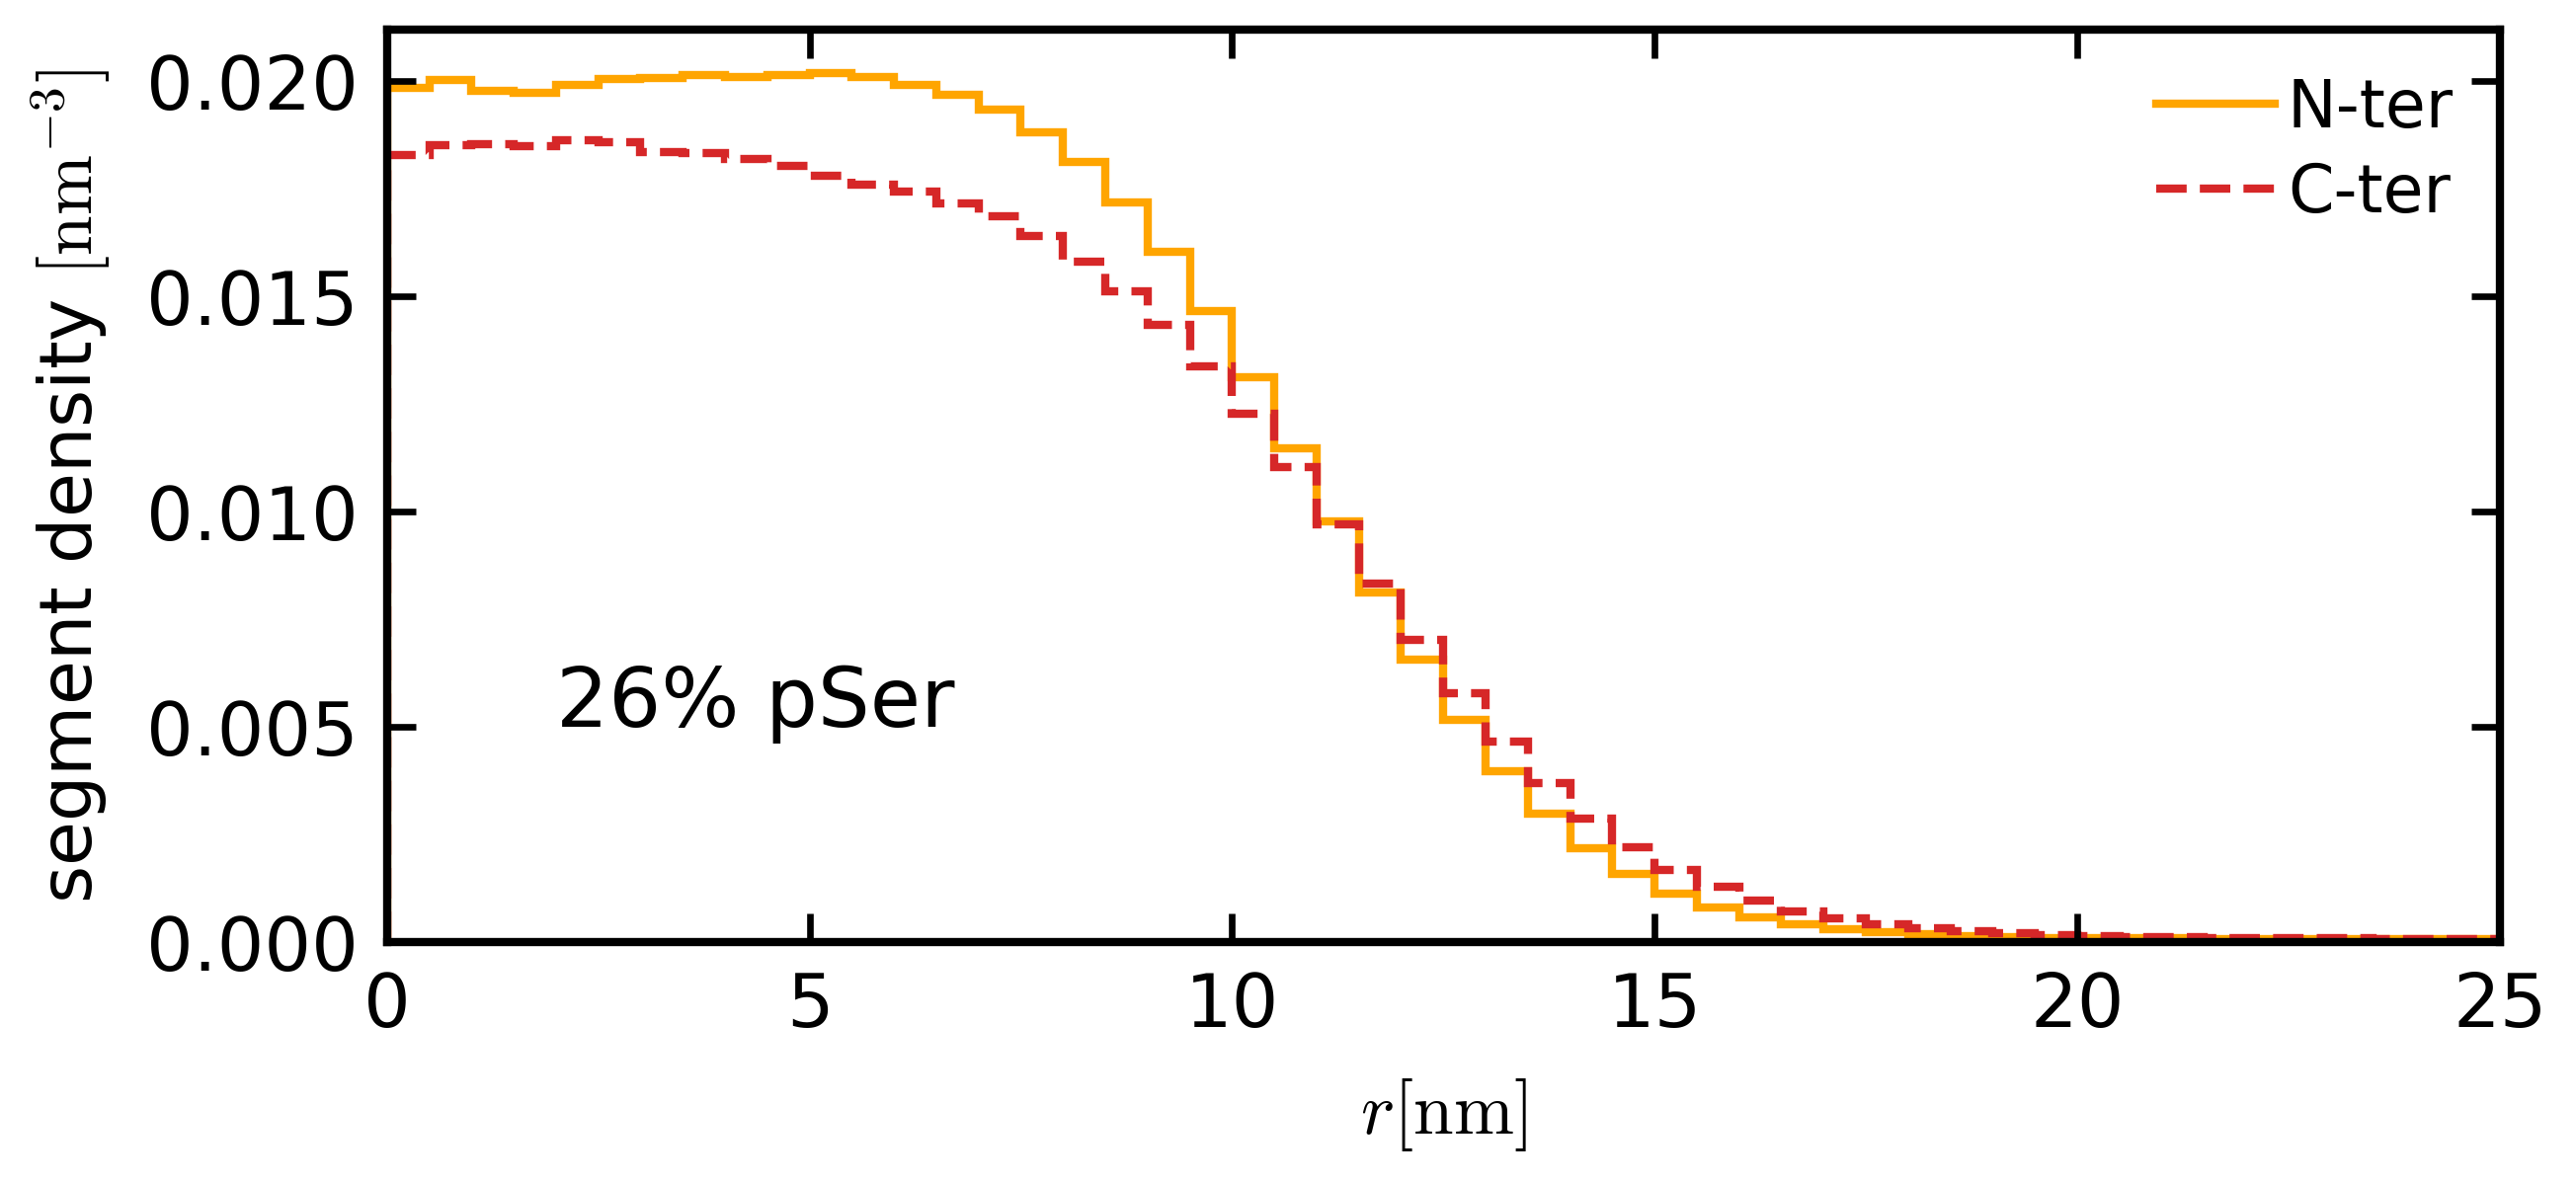

In [6]:
# N-ter vs C-ter around PP3 droplets (density per segment)
f, axes = plt.subplots(2, 1, figsize=(3.7, 3.3), sharex=True)
plt.subplots_adjust(hspace=0.2)
for ax, npser, text in zip(axes, (0, 1257), ('0% pSer', f'{pct_drop}% pSer')):
    ax.stairs(rho_drop['pp3', npser, 'nter'] / 100, x_stairs, color='orange', label='N-ter')
    ax.stairs(rho_drop['pp3', npser, 'cter'] / 54, x_stairs, color='tab:red', ls='--', label='C-ter')
    ax.legend(ncols=1, frameon=False)
    ax.text(25, 0.005, text)
    ax.set_xlim(0, 35)
axes[1].set_xlabel(r'$r [\mathrm{nm}]$')
axes[0].text(-7, 0., r'segment density $[\mathrm{nm}^{-3}]$', va='center', rotation='vertical')
savefig(path_struct_pl + 'radial_density_200-tdp43-lcd_5-pp3_n-vs-c-ter', dpi=1200)

# N-ter vs C-ter around CK1d droplets with 26% pSer
f, ax1 = plt.subplots(1, 1, figsize=(4.6, 2.))
ax1.stairs(rho_drop['ck1d', 1257, 'nter'] / 100, x_stairs, color='orange', label='N-ter')
ax1.stairs(rho_drop['ck1d', 1257, 'cter'] / 54, x_stairs, color='tab:red', ls='--', label='C-ter')
ax1.legend(ncols=1, frameon=False)
ax1.set_xlabel(r'$r [\mathrm{nm}]$', fontsize=8.8)
ax1.set_ylabel(r'segment density $[\mathrm{nm}^{-3}]$', fontsize=8.8)
ax1.text(2, 0.005, f'{pct_drop}% pSer')
ax1.set_xlim(0, 25)
savefig(path_struct_pl + 'radial_density_200-tdp43-lcd_5-ck1d-open_n-vs-c-ter', dpi=1200)

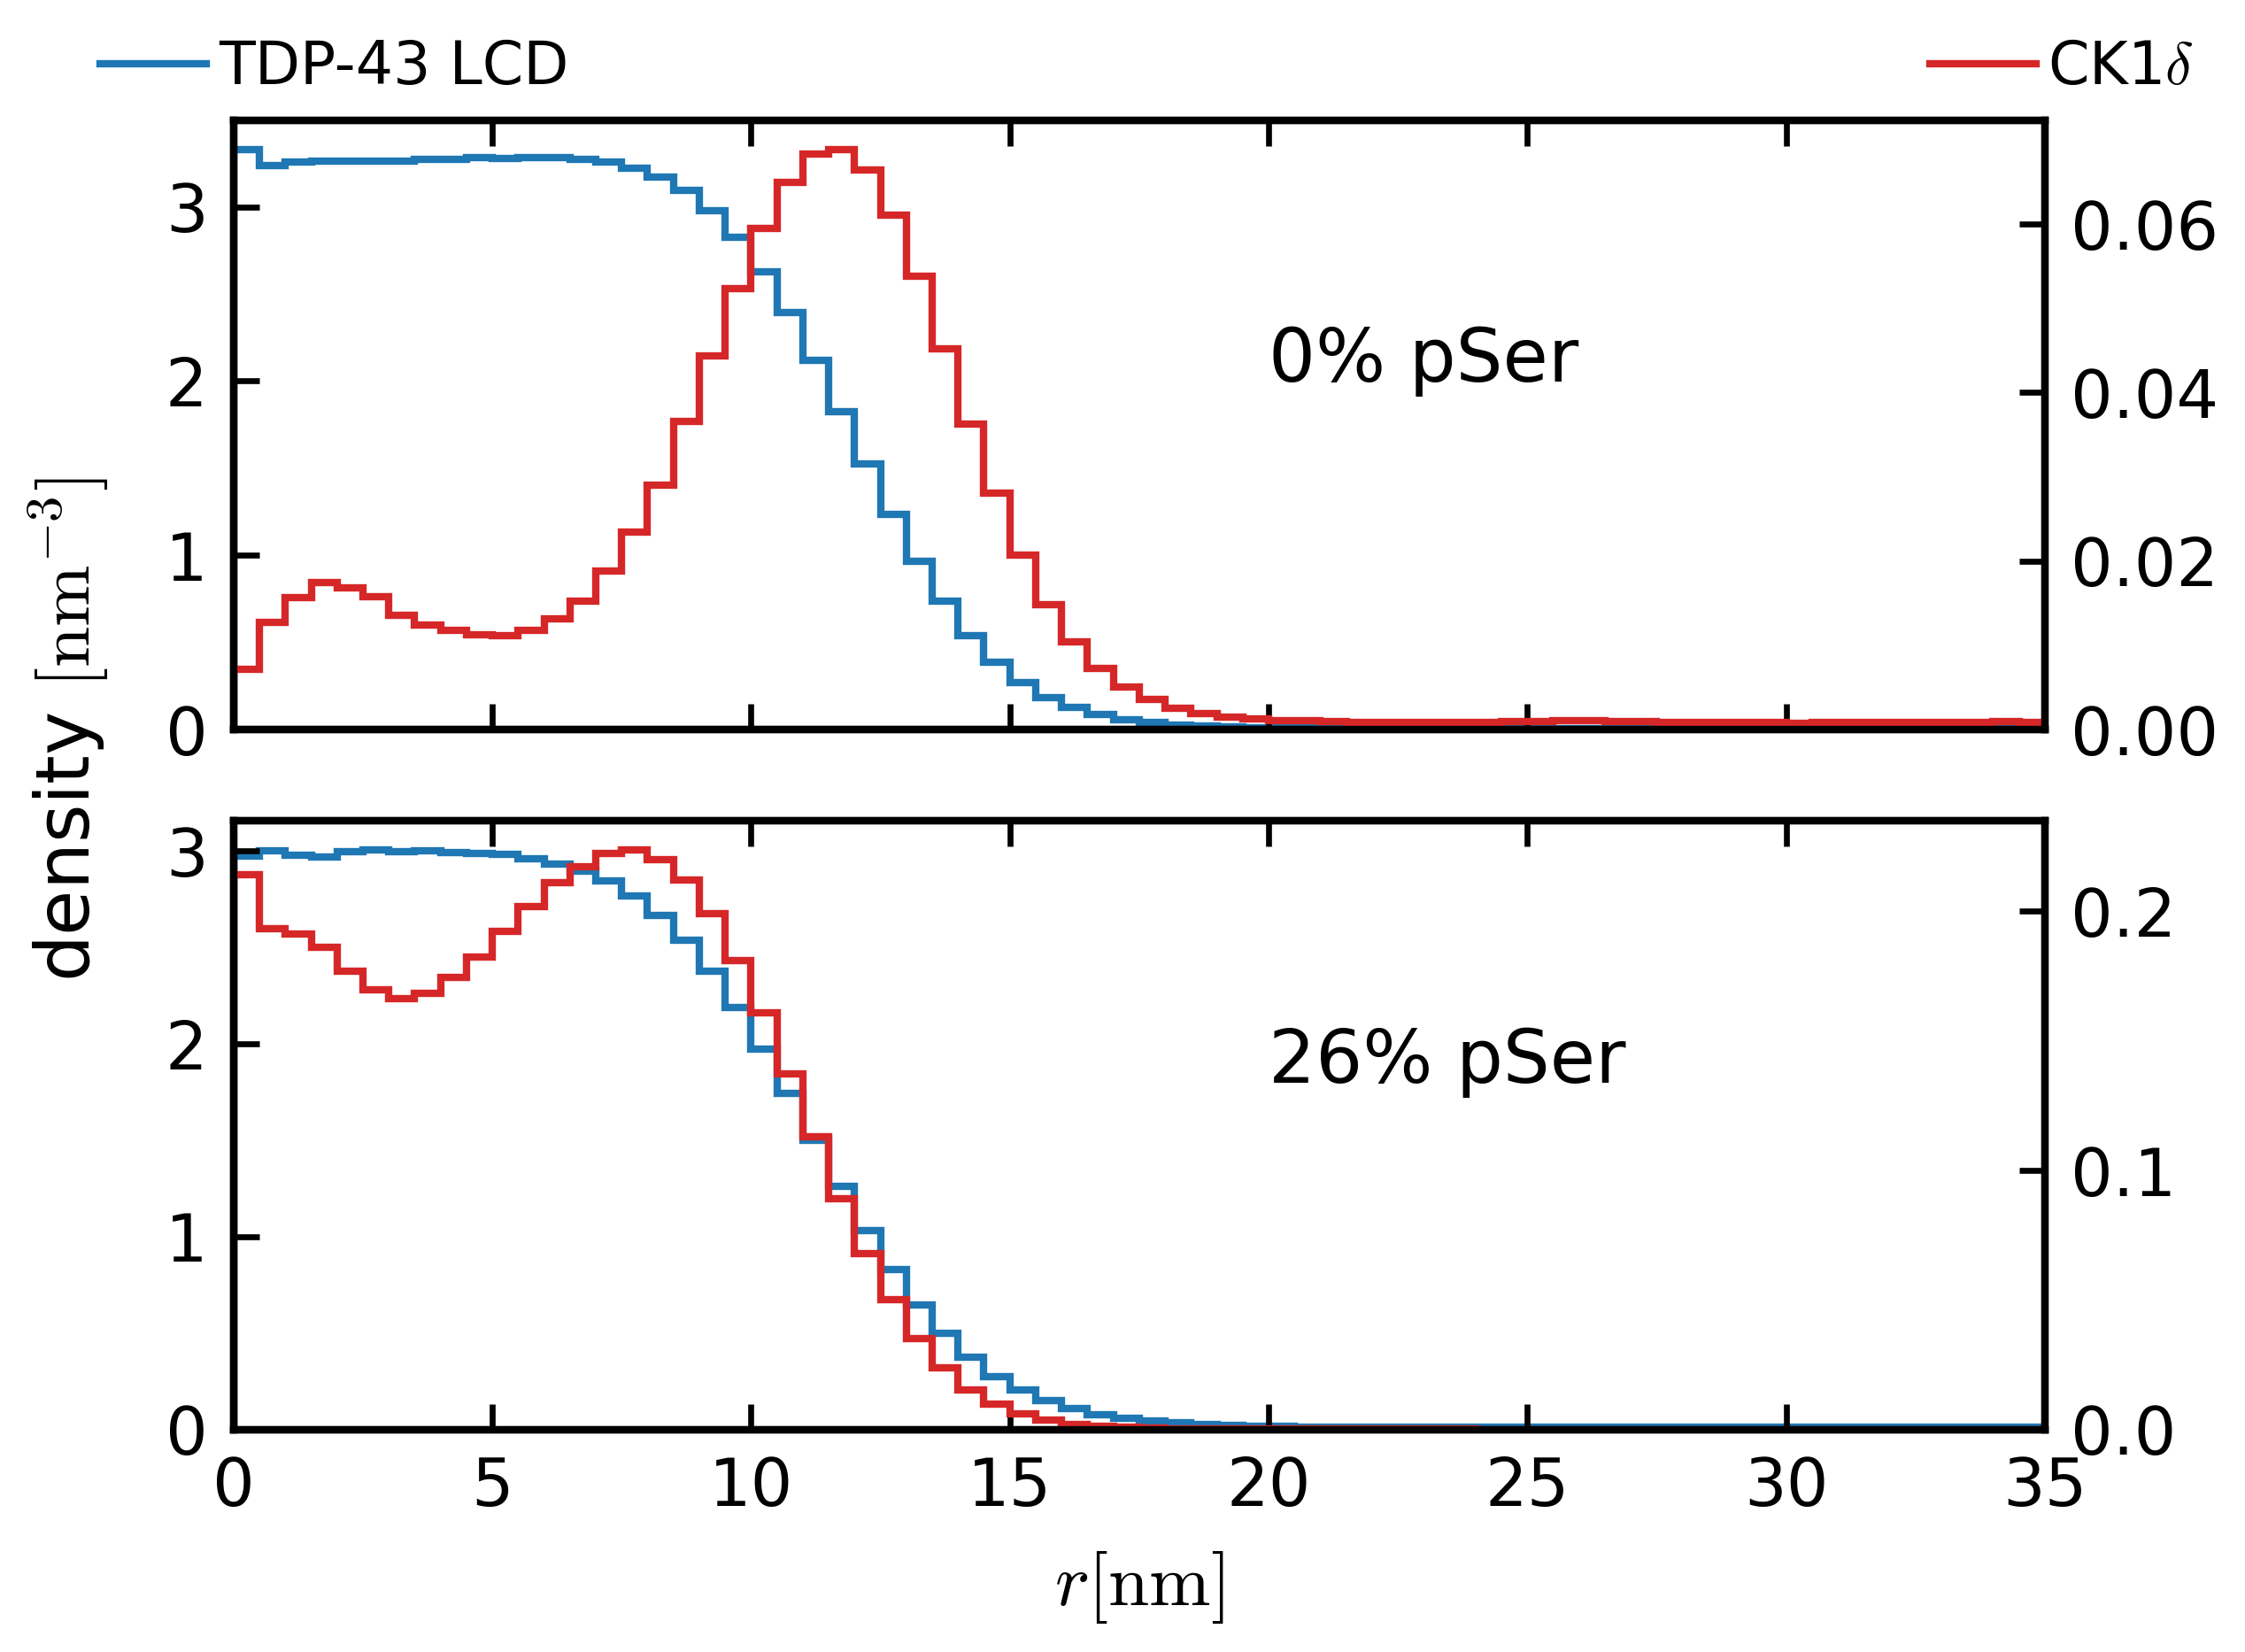

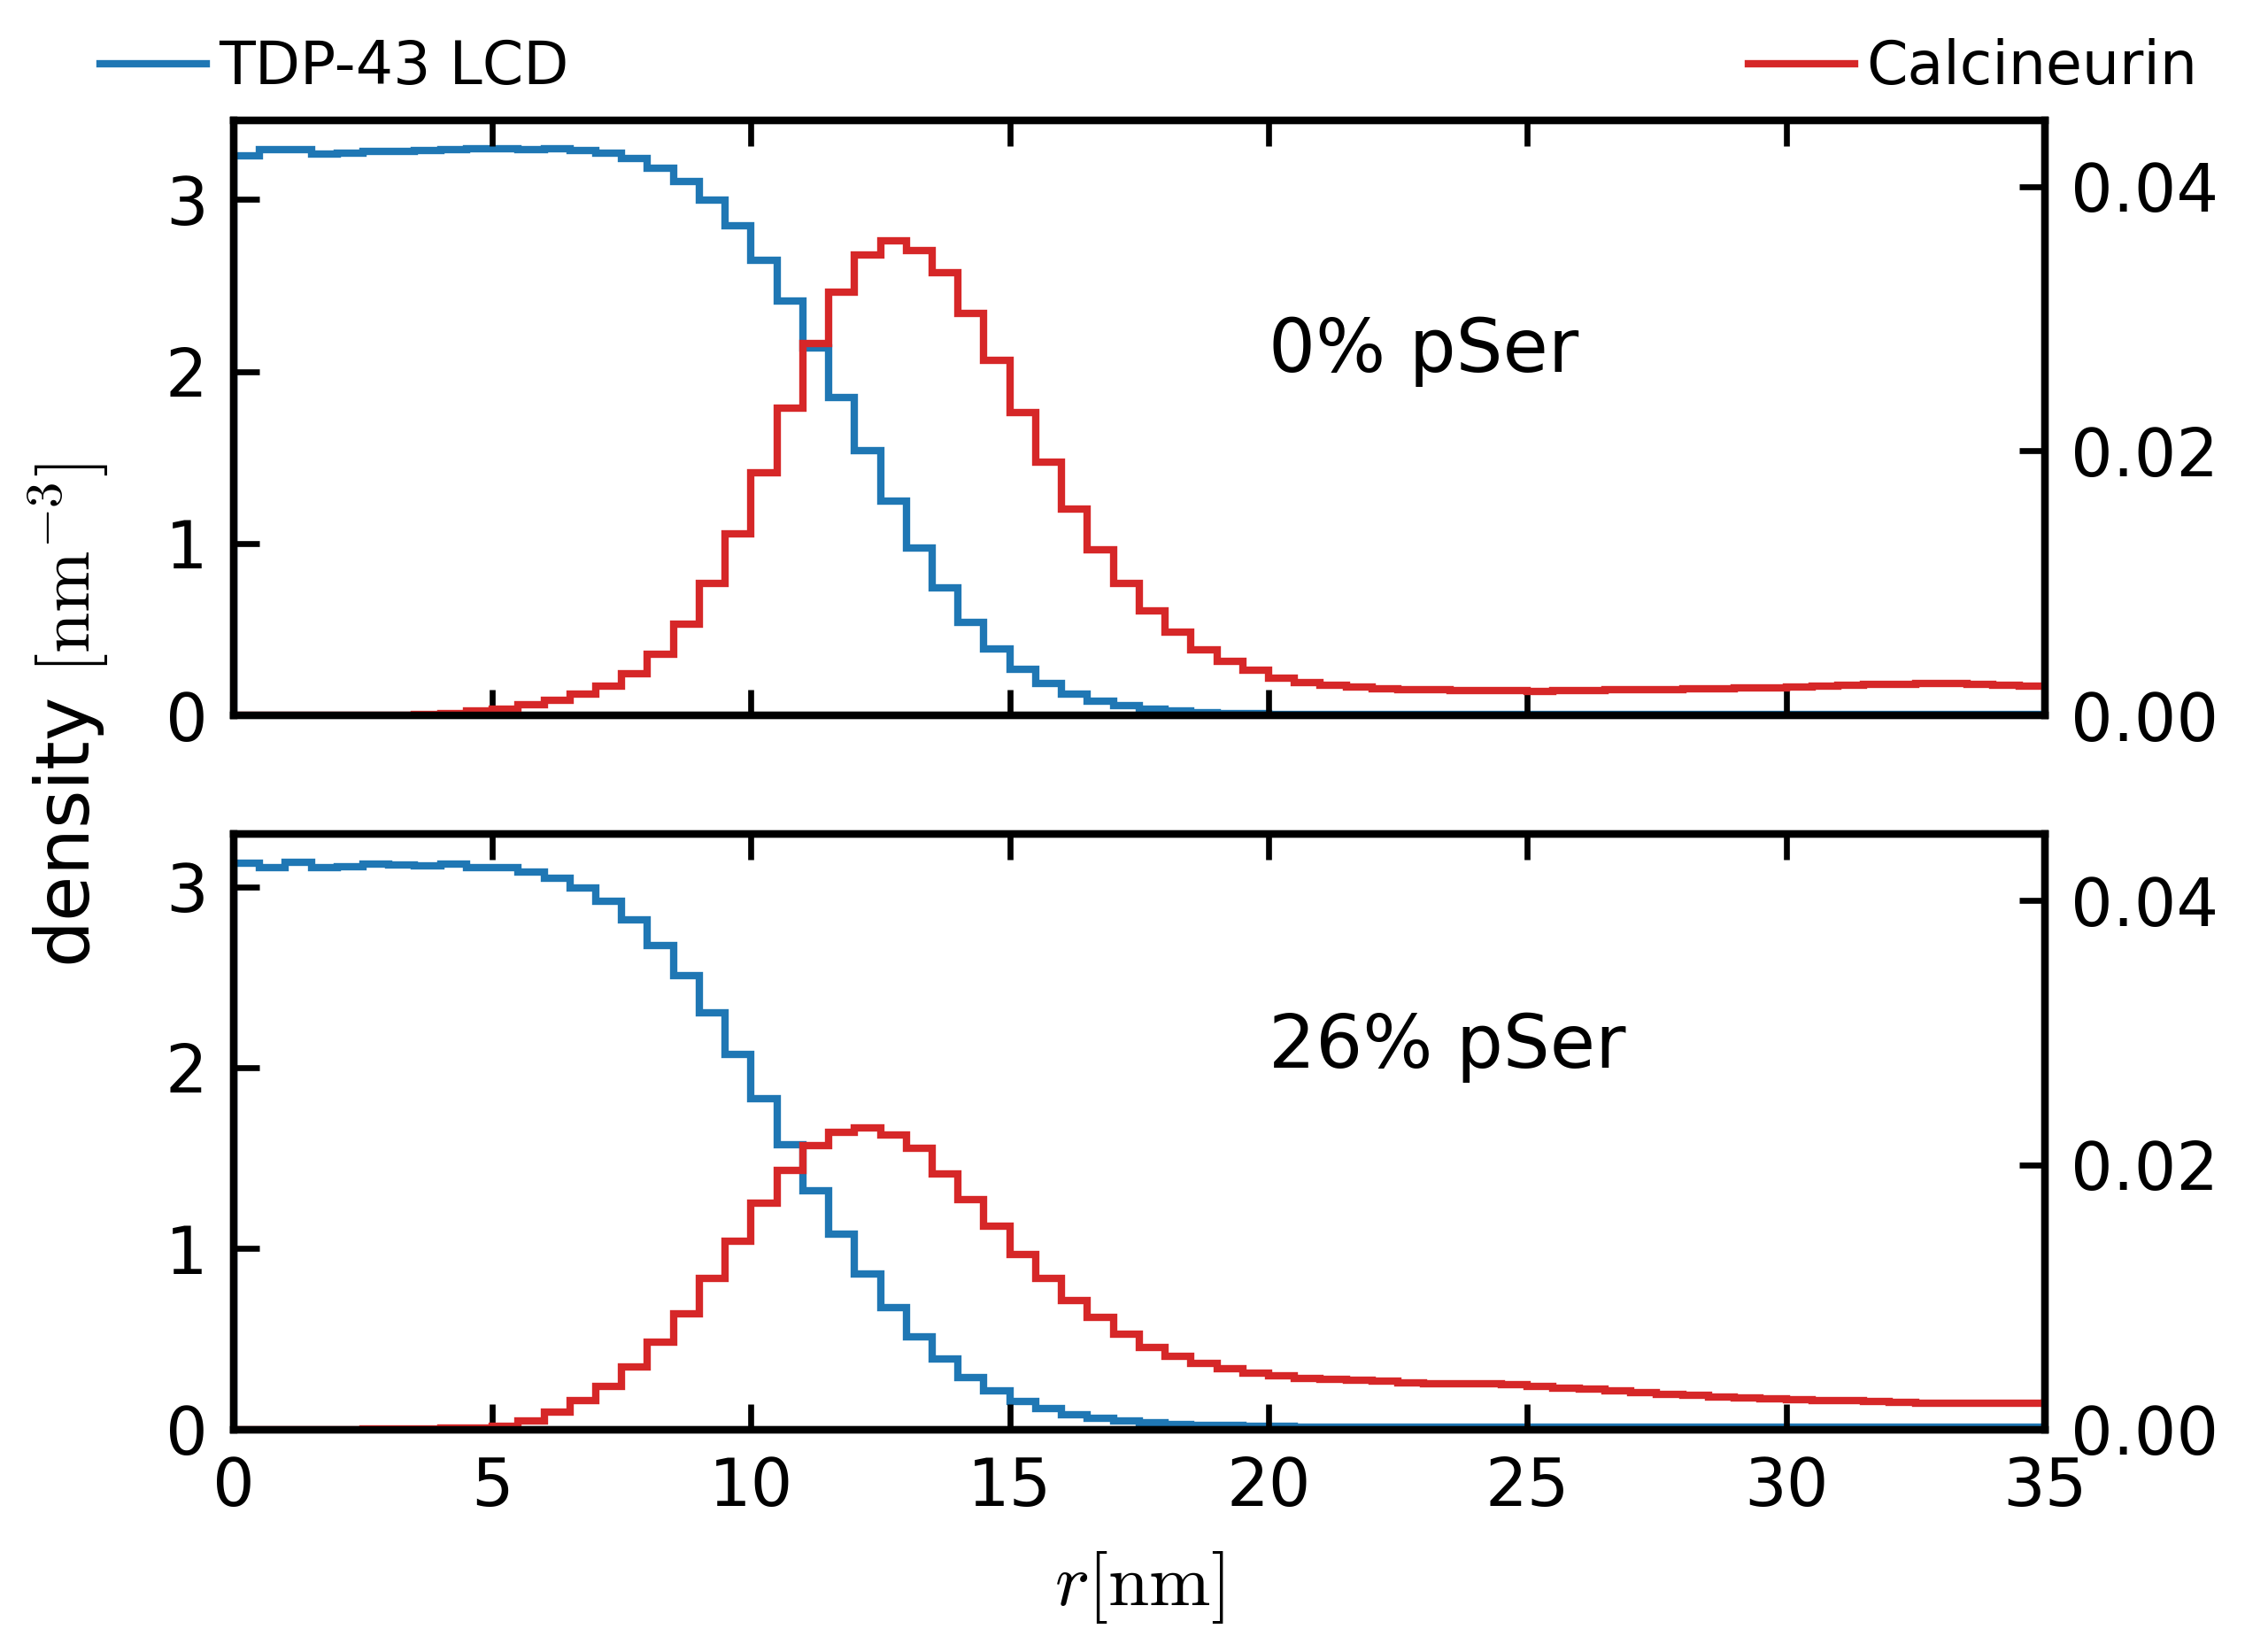

In [7]:
def plot_drop_enzyme(enzyme, label, ylabel, texts, legend_x, hspace, enz_ylim=None):
    '''TDP-43 LCD (left axis) and enzyme (right axis) radial densities without and with pSer.'''
    f, axes = plt.subplots(2, 1, figsize=(4.4, 3.2), sharex=True)
    plt.subplots_adjust(hspace=hspace)
    for ax, npser, (tx, ty, text) in zip(axes, (0, 1257), texts):
        axr = ax.twinx()
        axr.stairs(rho_drop[enzyme, npser, 'enz'], x_stairs, color='tab:red', label=label)
        ax.stairs(rho_drop[enzyme, npser, 'tdp'], x_stairs, color='tab:blue', label='TDP-43 LCD')
        ax.text(tx, ty, text)
        ax.set_xlim(0, 35)
        if enz_ylim is not None:
            axr.set_ylim(0, enz_ylim)
        if npser == 0:
            ax.legend(loc=(-0.08, 1.02), ncols=3, frameon=False)
            axr.legend(loc=(legend_x, 1.02), ncols=3, frameon=False)
    axes[1].set_xlabel(r'$r [\mathrm{nm}]$')
    axes[0].text(-4., 0., ylabel, va='center', rotation='vertical')


plot_drop_enzyme('ck1d', r'CK1$\delta$', r'density $[\mathrm{nm}^{-3}]$', [(20, 2., '0% pSer'), (20, 1.8, f'{pct_drop}% pSer')],
                 legend_x=0.93, hspace=0.15)
savefig(path_struct_pl + 'radial_density_200-tdp43-lcd_5-ck1d-open', dpi=1200)

plot_drop_enzyme('pp3', 'Calcineurin', r'density $[\mathrm{nm}^{-3}]$', [(20, 2., '0% pSer'), (20, 2., f'{pct_drop}% pSer')],
                 legend_x=0.83, hspace=0.2, enz_ylim=0.045)
savefig(path_struct_pl + 'radial_density_200-tdp43-lcd_5-pp3', dpi=1200)

# 2. Slabs
## Phase diagram vs pSer per chain
Density profiles of every slab (saved to the analysis folder, computed only if missing), then tanh fits of the symmetrised
profiles. Errors: standard error over the 3 replicas. At 10-11 pSer per chain the slab is homogeneous: the fit (with an
`OptimizeWarning`) only follows the small bump left by the centring, so dense and dilute values there are not two phases.

In [8]:
NPSER_SLAB = list(range(5, 12))
N_SIMS = 3
n_bins = 200


def slab_profile_prefix(npser, s):
    return (path_pser_an + f'sim_eq_slab_200-tdp43-lcd-{npser}pser/'
            f'density_profile_sim{s}_eq_slab_CAL3_200-tdp43-lcd_{npser}pser')


for npser in NPSER_SLAB:
    for s in range(1, N_SIMS + 1):
        prefix = slab_profile_prefix(npser, s)
        if os.path.exists(prefix + 'densities.txt') and not RECOMPUTE:
            continue
        filein = path_pser + f'sim_eq_slab_200-tdp43-lcd-{npser}pser/sim{s}_eq_slab_200-tdp43-lcd-{npser}pser_CAL3_fr01_dump_centered.gsd'
        print(npser, s, 'pSer beads:', np.sum(gsd.hoomd.open(filein, 'r')[0].particles.typeid == 20))
        r_centers, rho = hpap.compute_density_profile(filein, nbins=n_bins, therm=500)
        np.savetxt(prefix + 'bins.txt', r_centers)
        np.savetxt(prefix + 'densities.txt', rho)

5 1 pSer beads: 1000
5 2 pSer beads: 1000
5 3 pSer beads: 1000
6 1 pSer beads: 1200
6 2 pSer beads: 1200
6 3 pSer beads: 1200
7 1 pSer beads: 1400
7 2 pSer beads: 1400
7 3 pSer beads: 1400
8 1 pSer beads: 1600
8 2 pSer beads: 1600
8 3 pSer beads: 1600
9 1 pSer beads: 1800
9 2 pSer beads: 1800
9 3 pSer beads: 1800
10 1 pSer beads: 2000
10 2 pSer beads: 2000
10 3 pSer beads: 2000
11 1 pSer beads: 2200
11 2 pSer beads: 2200
11 3 pSer beads: 2200


5 1 [ 1.43133702 -1.40685531  0.31507045 10.43600412]
5 2 [ 1.41517539 -1.4004656   0.33552188 10.83366572]
5 3 [ 1.40053833 -1.39300372  0.3335191  11.1493983 ]
6 1 [ 1.3084947  -1.2915769   0.28284094 11.66026269]
6 2 [ 1.29173208 -1.27483228  0.28542633 11.81450146]
6 3 [ 1.35107437 -1.33753013  0.28941636 11.38572567]
7 1 [ 1.21110613 -1.18778961  0.23230173 12.40566704]
7 2 [ 1.17934829 -1.14137021  0.22663238 12.26648033]
7 3 [ 1.1410537  -1.10567808  0.22113522 12.78095802]
8 1 [ 0.86227843 -0.66997555  0.13085838  9.05350622]
8 2 [ 0.98253918 -0.79058154  0.17698631  7.81127735]
8 3 [ 0.74437632 -0.54224701  0.1163583  10.33009029]
9 1 [ 0.48399463 -0.22923062  0.10684906 13.58320394]
9 2 [ 0.85182588 -0.68229233  0.02459863 -6.73322293]
9 3 [  0.45772277   0.19934421 -52.88614285  15.1114254 ]
10 1 [ 0.37551919 -0.10299198  0.11066556 22.13064571]
10 2 [ 0.36166763 -0.08207846  0.11440077 23.48944598]
10 3 [ 0.37252348 -0.09294635  0.18124298 20.76571178]
11 1 [ 0.34961708 -0.

/tmp/ipykernel_3745028/1467511888.py:8: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, pcov = curve_fit(tanh_general, x, y)


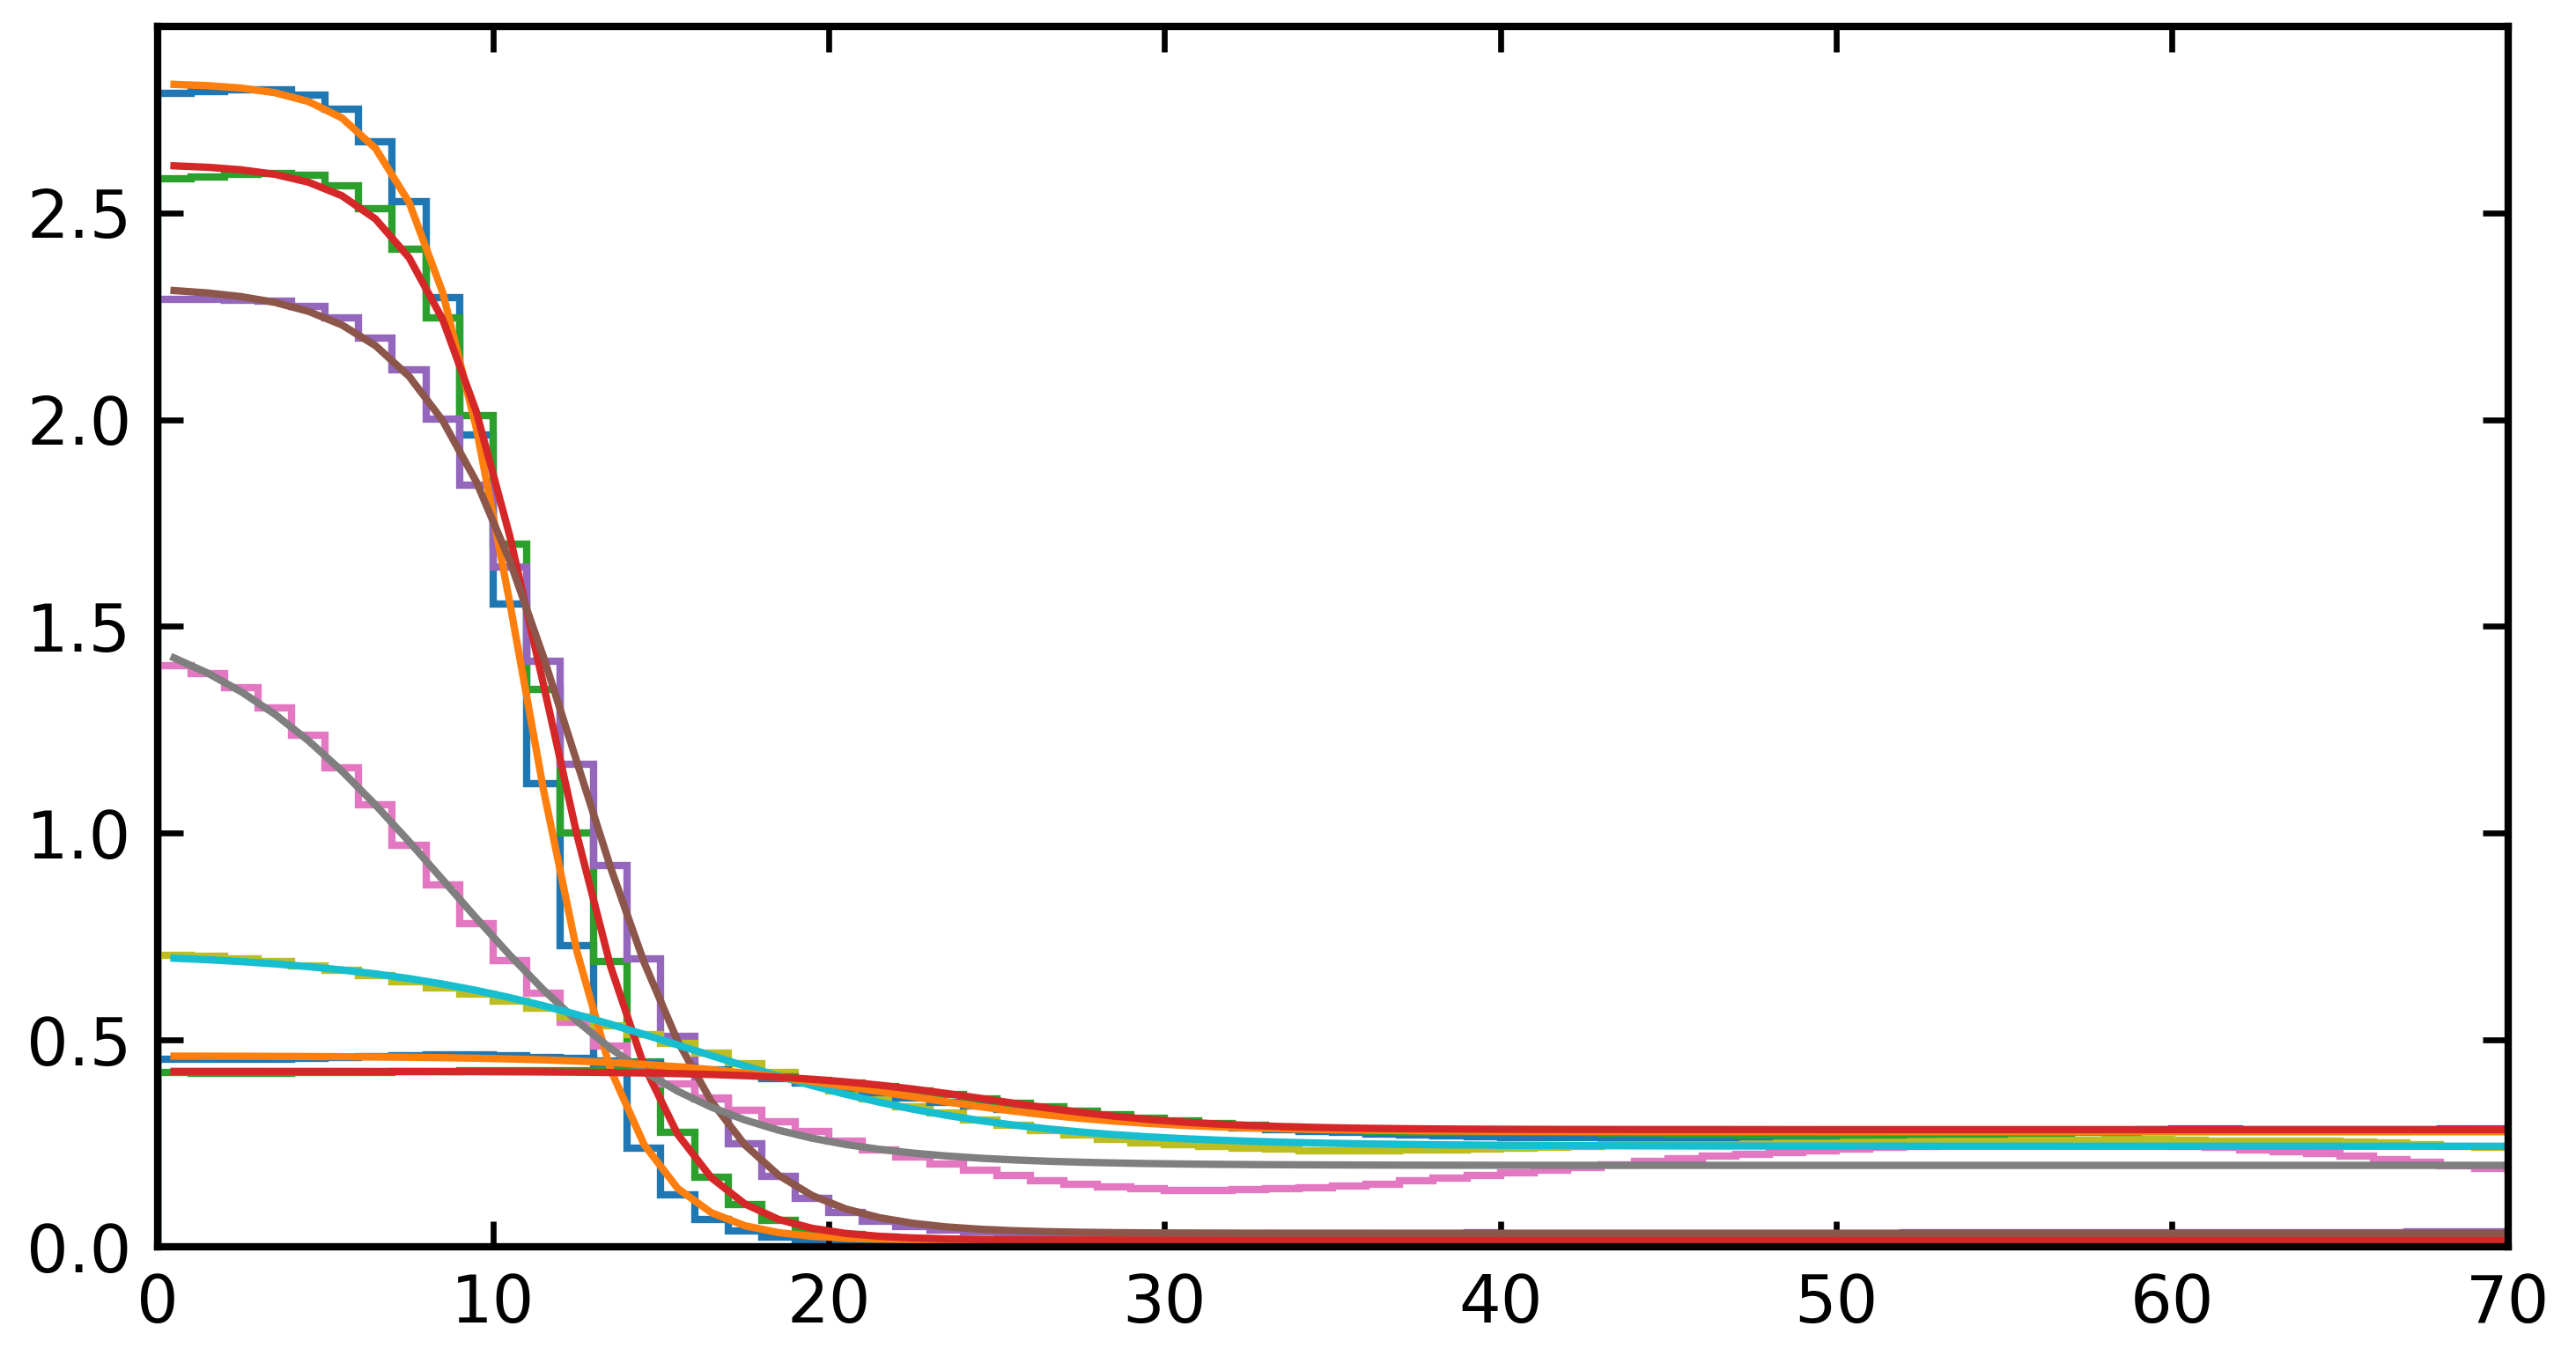

In [9]:
c_cond, c_dil, err_cond, err_dil = [], [], [], []
for npser in NPSER_SLAB:
    c_cond_tmp, c_dil_tmp, profiles = [], [], []
    for s in range(1, N_SIMS + 1):
        r_centers = np.loadtxt(slab_profile_prefix(npser, s) + 'bins.txt')
        rho = np.loadtxt(slab_profile_prefix(npser, s) + 'densities.txt')
        x, y = r_centers[n_bins // 2:], symmetric_half(rho)
        popt, pcov = curve_fit(tanh_general, x, y)
        print(npser, s, popt)
        c_cond_tmp.append(popt[0] + np.abs(popt[1]))
        c_dil_tmp.append(popt[0] - np.abs(popt[1]))
        profiles.append(rho)

    c_cond.append(np.mean(c_cond_tmp))
    c_dil.append(np.mean(c_dil_tmp))
    err_cond.append(np.std(c_cond_tmp, ddof=1) / np.sqrt(N_SIMS))      # standard error over the replicas
    err_dil.append(np.std(c_dil_tmp, ddof=1) / np.sqrt(N_SIMS))

    # average profile of the replicas and its fit
    y = symmetric_half(np.mean(profiles, axis=0))
    popt, _ = curve_fit(tanh_general, x, y)
    plt.stairs(y, stairs_edges(x))
    plt.plot(x, tanh_general(x, *popt))
plt.xlim(0, 70)
plt.show()

c_cond, c_dil = np.array(c_cond), np.array(c_dil)

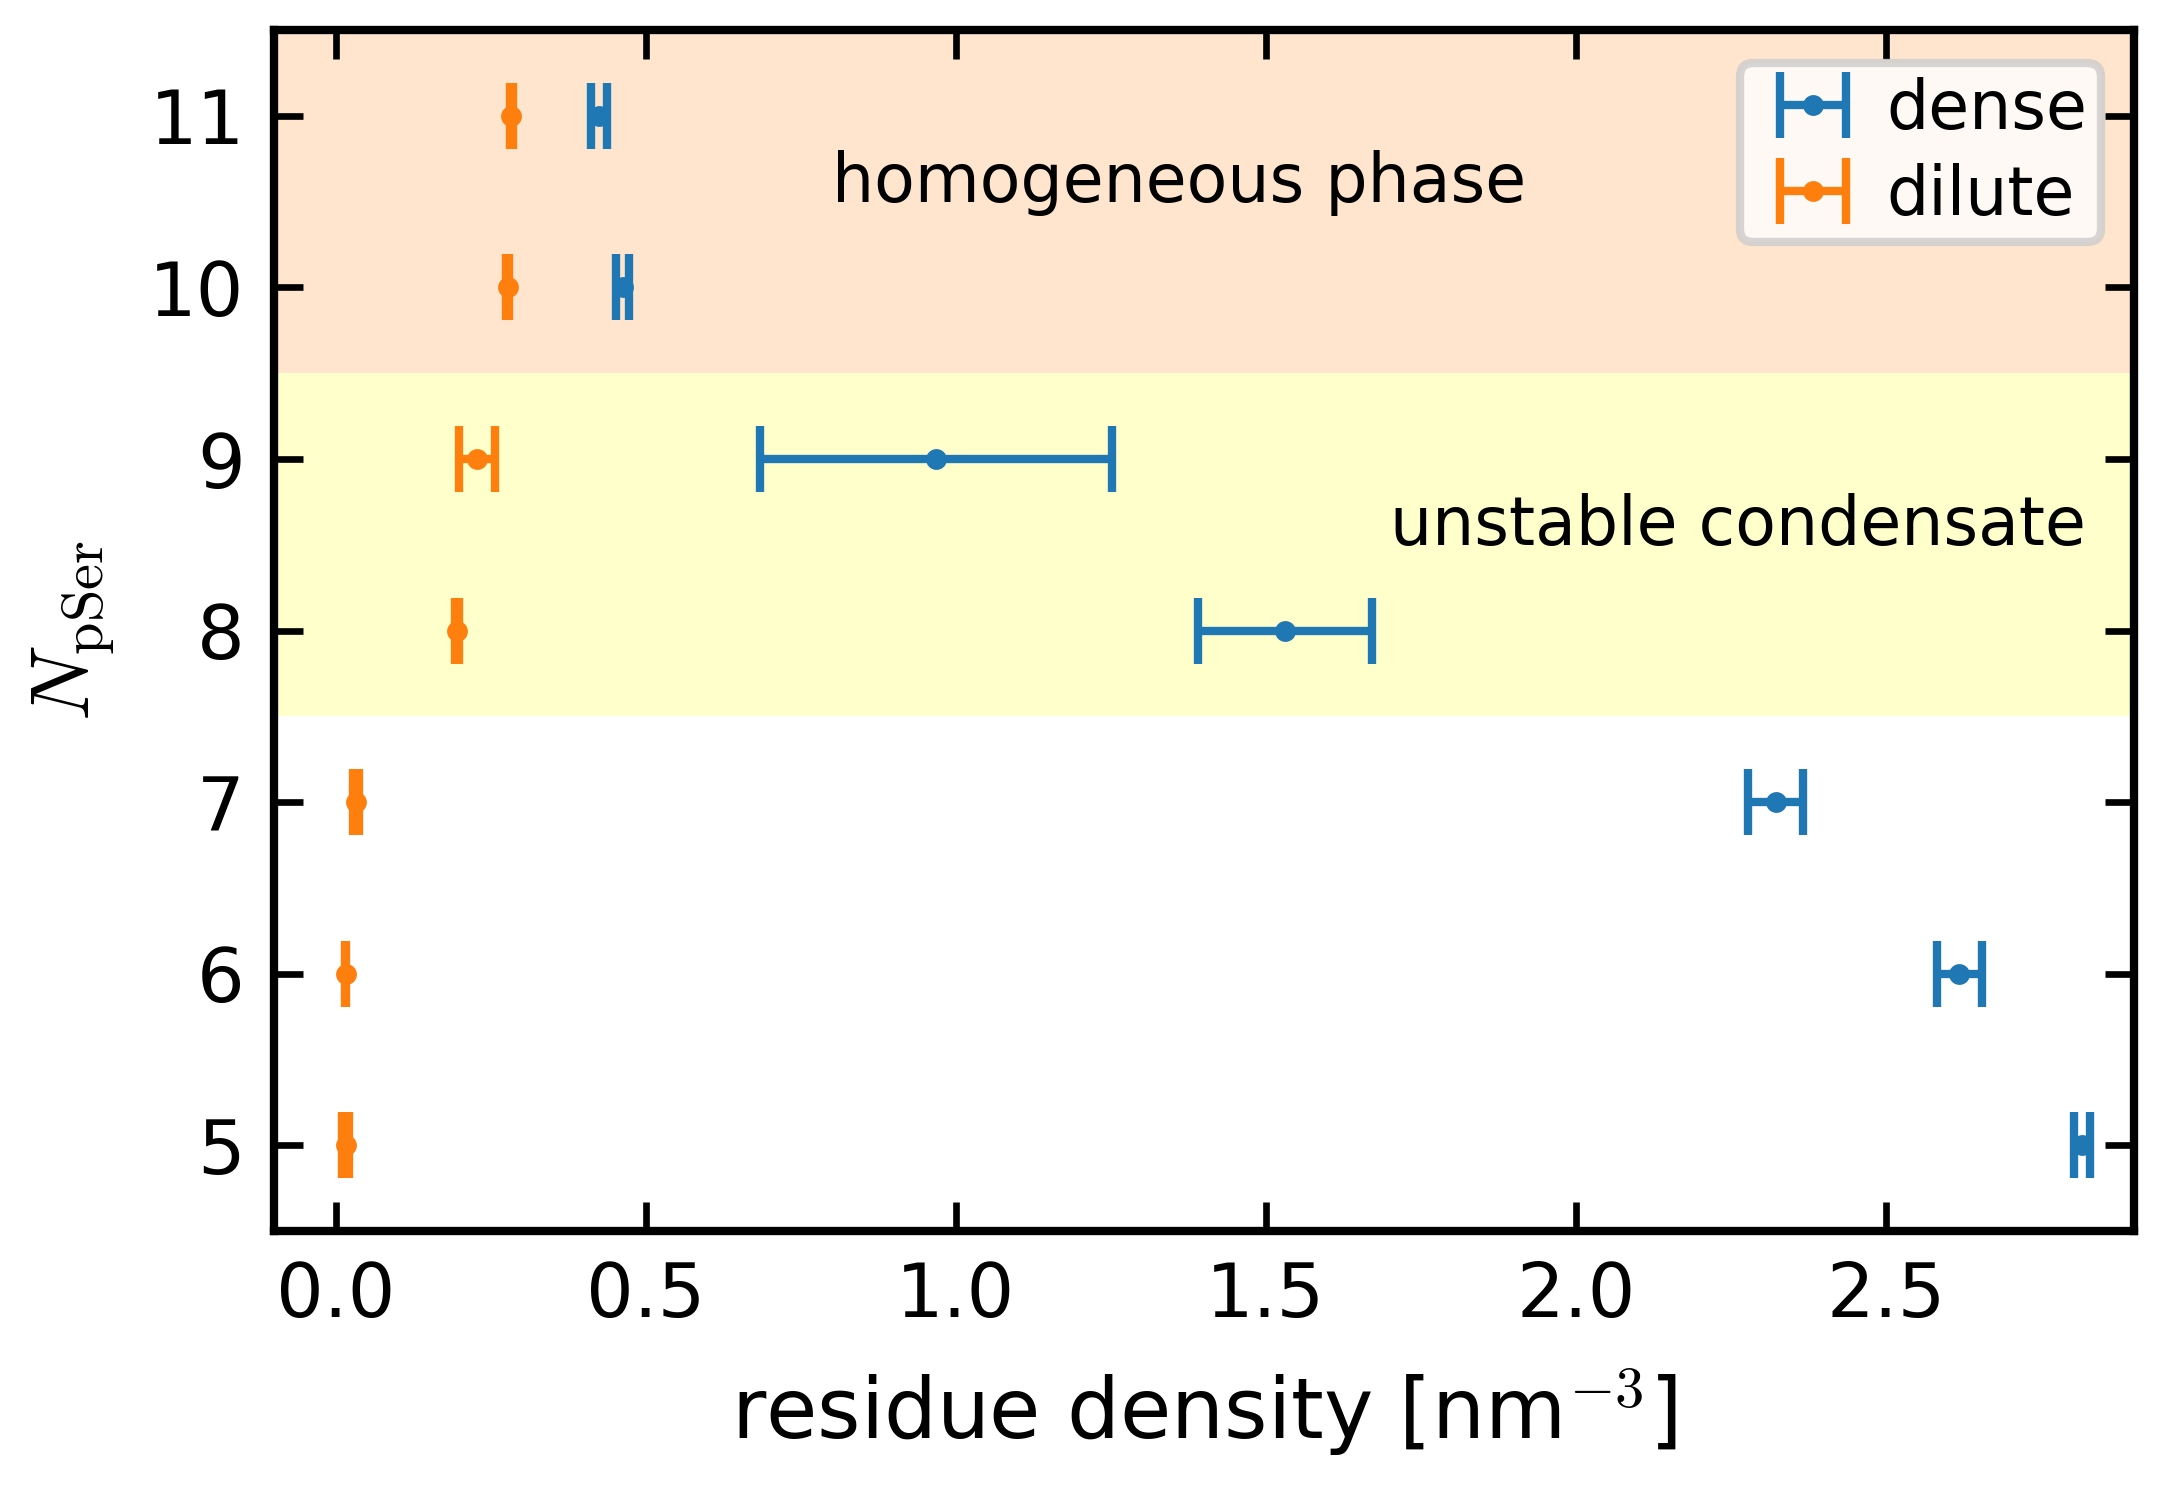

In [10]:
plt.figure(figsize=(4, 2.6))
plt.errorbar(c_cond, NPSER_SLAB, xerr=err_cond, fmt='.', capsize=4, label='dense')
plt.errorbar(c_dil, NPSER_SLAB, xerr=err_dil, fmt='.', capsize=4, label='dilute')
plt.fill_between([-1, 10], [7.5, 7.5], [9.5, 9.5], color='yellow', alpha=0.2, lw=0.)
plt.fill_between([-1, 10], [9.5, 9.5], [12.5, 12.5], color='tab:orange', alpha=0.2, lw=0.)
plt.xlabel(r'residue density [nm$^{-3}$]')
plt.ylabel(r'$N_{\mathrm{pSer}}$')
plt.text(1.7, 8.5, 'unstable condensate', fontsize=8)
plt.text(0.8, 10.5, 'homogeneous phase', fontsize=8)
plt.xlim(-0.1, 2.9)
plt.ylim(4.5, 11.5)
plt.legend()
savefig(path_pser_pl + 'phase_diagram_slab_pser')

## Position of the enzymes
TDP-43 (left axis) and enzyme (right axis) density along z; CALVADOS3 (solid) vs HPS-Urry (dashed).

In [34]:
def slab_file(n_tdp_label, enzyme, model, npser, rep):
    '''Centred dump of replica rep; n_tdp_label: '150-full-tdp43' or '400-tdp43-lcd'; npser: number of pSer or 0.'''
    enz = 'ck1d-open' if enzyme == 'ck1d' else 'pp3'
    name, pser = n_tdp_label.split('-', 1)
    tag = f'-{npser}pser' if npser else ''
    return (f'sim_eq_slab_{n_tdp_label}_5-{enz}_{model}_fr01/'
            f'sim{rep}_eq_slab_{name}-{"com-" if "full" in pser else ""}{pser}{tag}_5-com-{enz}_{model}_fr01_dump_centered.gsd')


def slab_profiles(system, enzyme, model, npser, n_tdp):
    '''z profiles of TDP-43 (first n_tdp beads) and of the 5 enzymes that follow them, averaged over the replicas.'''
    tdp_group = np.arange(n_tdp)
    enz_group = np.arange(n_tdp, n_tdp + 5 * ENZ_BEADS[enzyme])

    def compute(f):
        bins, tdp = hpap.compute_density_profile(f, axis=2, nbins=200, group=tdp_group, therm=100)
        bins_e, enz = hpap.compute_density_profile(f, axis=2, nbins=200, group=enz_group, therm=100)
        return dict(bins=bins, tdp=tdp, bins_e=bins_e, enz=enz, frames_used=dump_frames(f) - 100)

    # z_sim_eq_slab_..._fr01: name of the single-run profile (before the replicas)
    name = 'z_' + os.path.basename(slab_file(system, enzyme, model, npser, 1)).replace('sim1_', 'sim_', 1).replace('_dump_centered.gsd', '')
    p = replica_average(name, lambda r: path_struct + slab_file(system, enzyme, model, npser, r), compute, ('tdp', 'enz'),
                        old_file=prof_dir + name + '.npz')
    return p['bins'], p['tdp'], p['bins_e'], p['enz']


# (system, enzyme, model, npser) -> profiles
SLAB_SETS = {'150-full-tdp43': (62100, 922), '400-tdp43-lcd': (61600, 1715)}
slab = {}
for system, (n_tdp, npser) in SLAB_SETS.items():
    for enzyme in ('ck1d', 'pp3'):
        for model in ('CAL3', 'HPSu'):
            for n in (0, npser):
                print(system, enzyme, model, n)
                slab[system, enzyme, model, n] = slab_profiles(system, enzyme, model, n, n_tdp)

150-full-tdp43 ck1d CAL3 0
z_sim_eq_slab_150-com-full-tdp43_5-com-ck1d-open_CAL3_fr01: sim1 (4900 frames), sim2 (2400 frames)
150-full-tdp43 ck1d CAL3 922
z_sim_eq_slab_150-com-full-tdp43-922pser_5-com-ck1d-open_CAL3_fr01: sim1 (4900 frames), sim2 (2400 frames)
150-full-tdp43 ck1d HPSu 0
z_sim_eq_slab_150-com-full-tdp43_5-com-ck1d-open_HPSu_fr01: sim1 (4900 frames), sim2 (2400 frames)
150-full-tdp43 ck1d HPSu 922
z_sim_eq_slab_150-com-full-tdp43-922pser_5-com-ck1d-open_HPSu_fr01: sim1 (4900 frames), sim2 (2400 frames)
150-full-tdp43 pp3 CAL3 0
z_sim_eq_slab_150-com-full-tdp43_5-com-pp3_CAL3_fr01: sim1 (4900 frames), sim2 (2400 frames)
150-full-tdp43 pp3 CAL3 922
z_sim_eq_slab_150-com-full-tdp43-922pser_5-com-pp3_CAL3_fr01: sim1 (4900 frames), sim2 (2400 frames)
150-full-tdp43 pp3 HPSu 0
z_sim_eq_slab_150-com-full-tdp43_5-com-pp3_HPSu_fr01: sim1 (4900 frames), sim2 (2400 frames)
150-full-tdp43 pp3 HPSu 922
z_sim_eq_slab_150-com-full-tdp43-922pser_5-com-pp3_HPSu_fr01: sim1 (4900 frames),

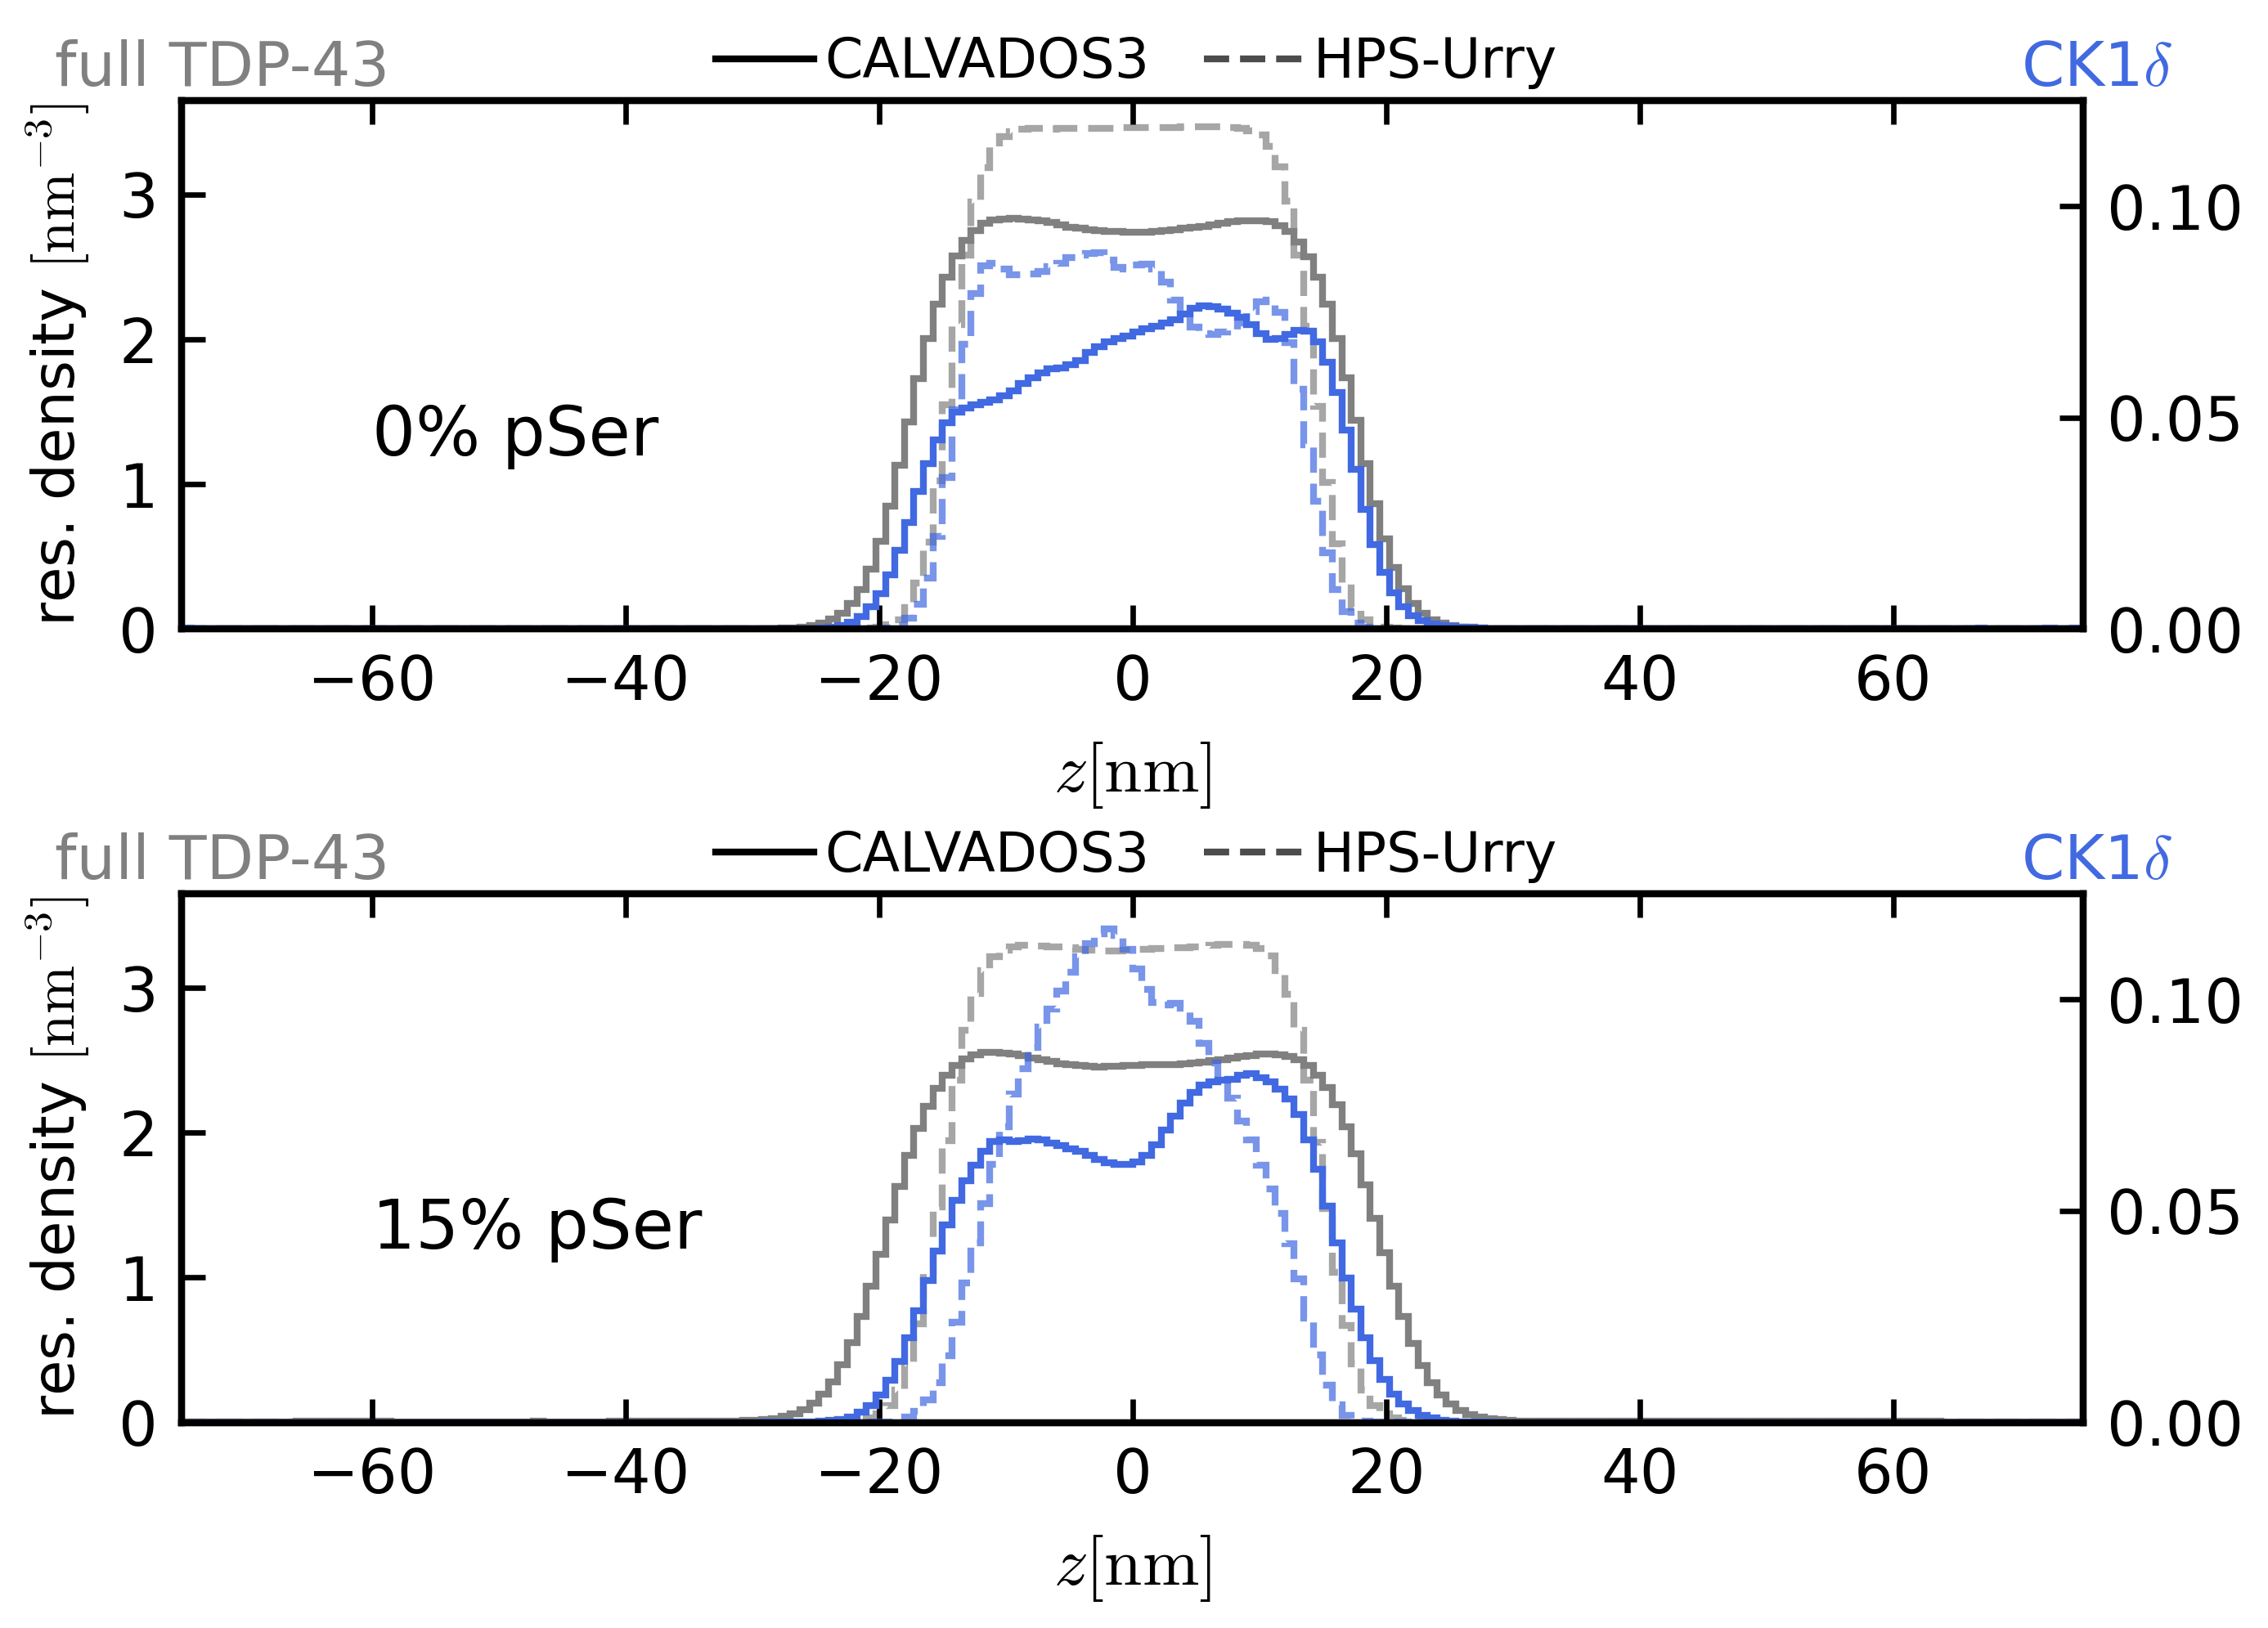

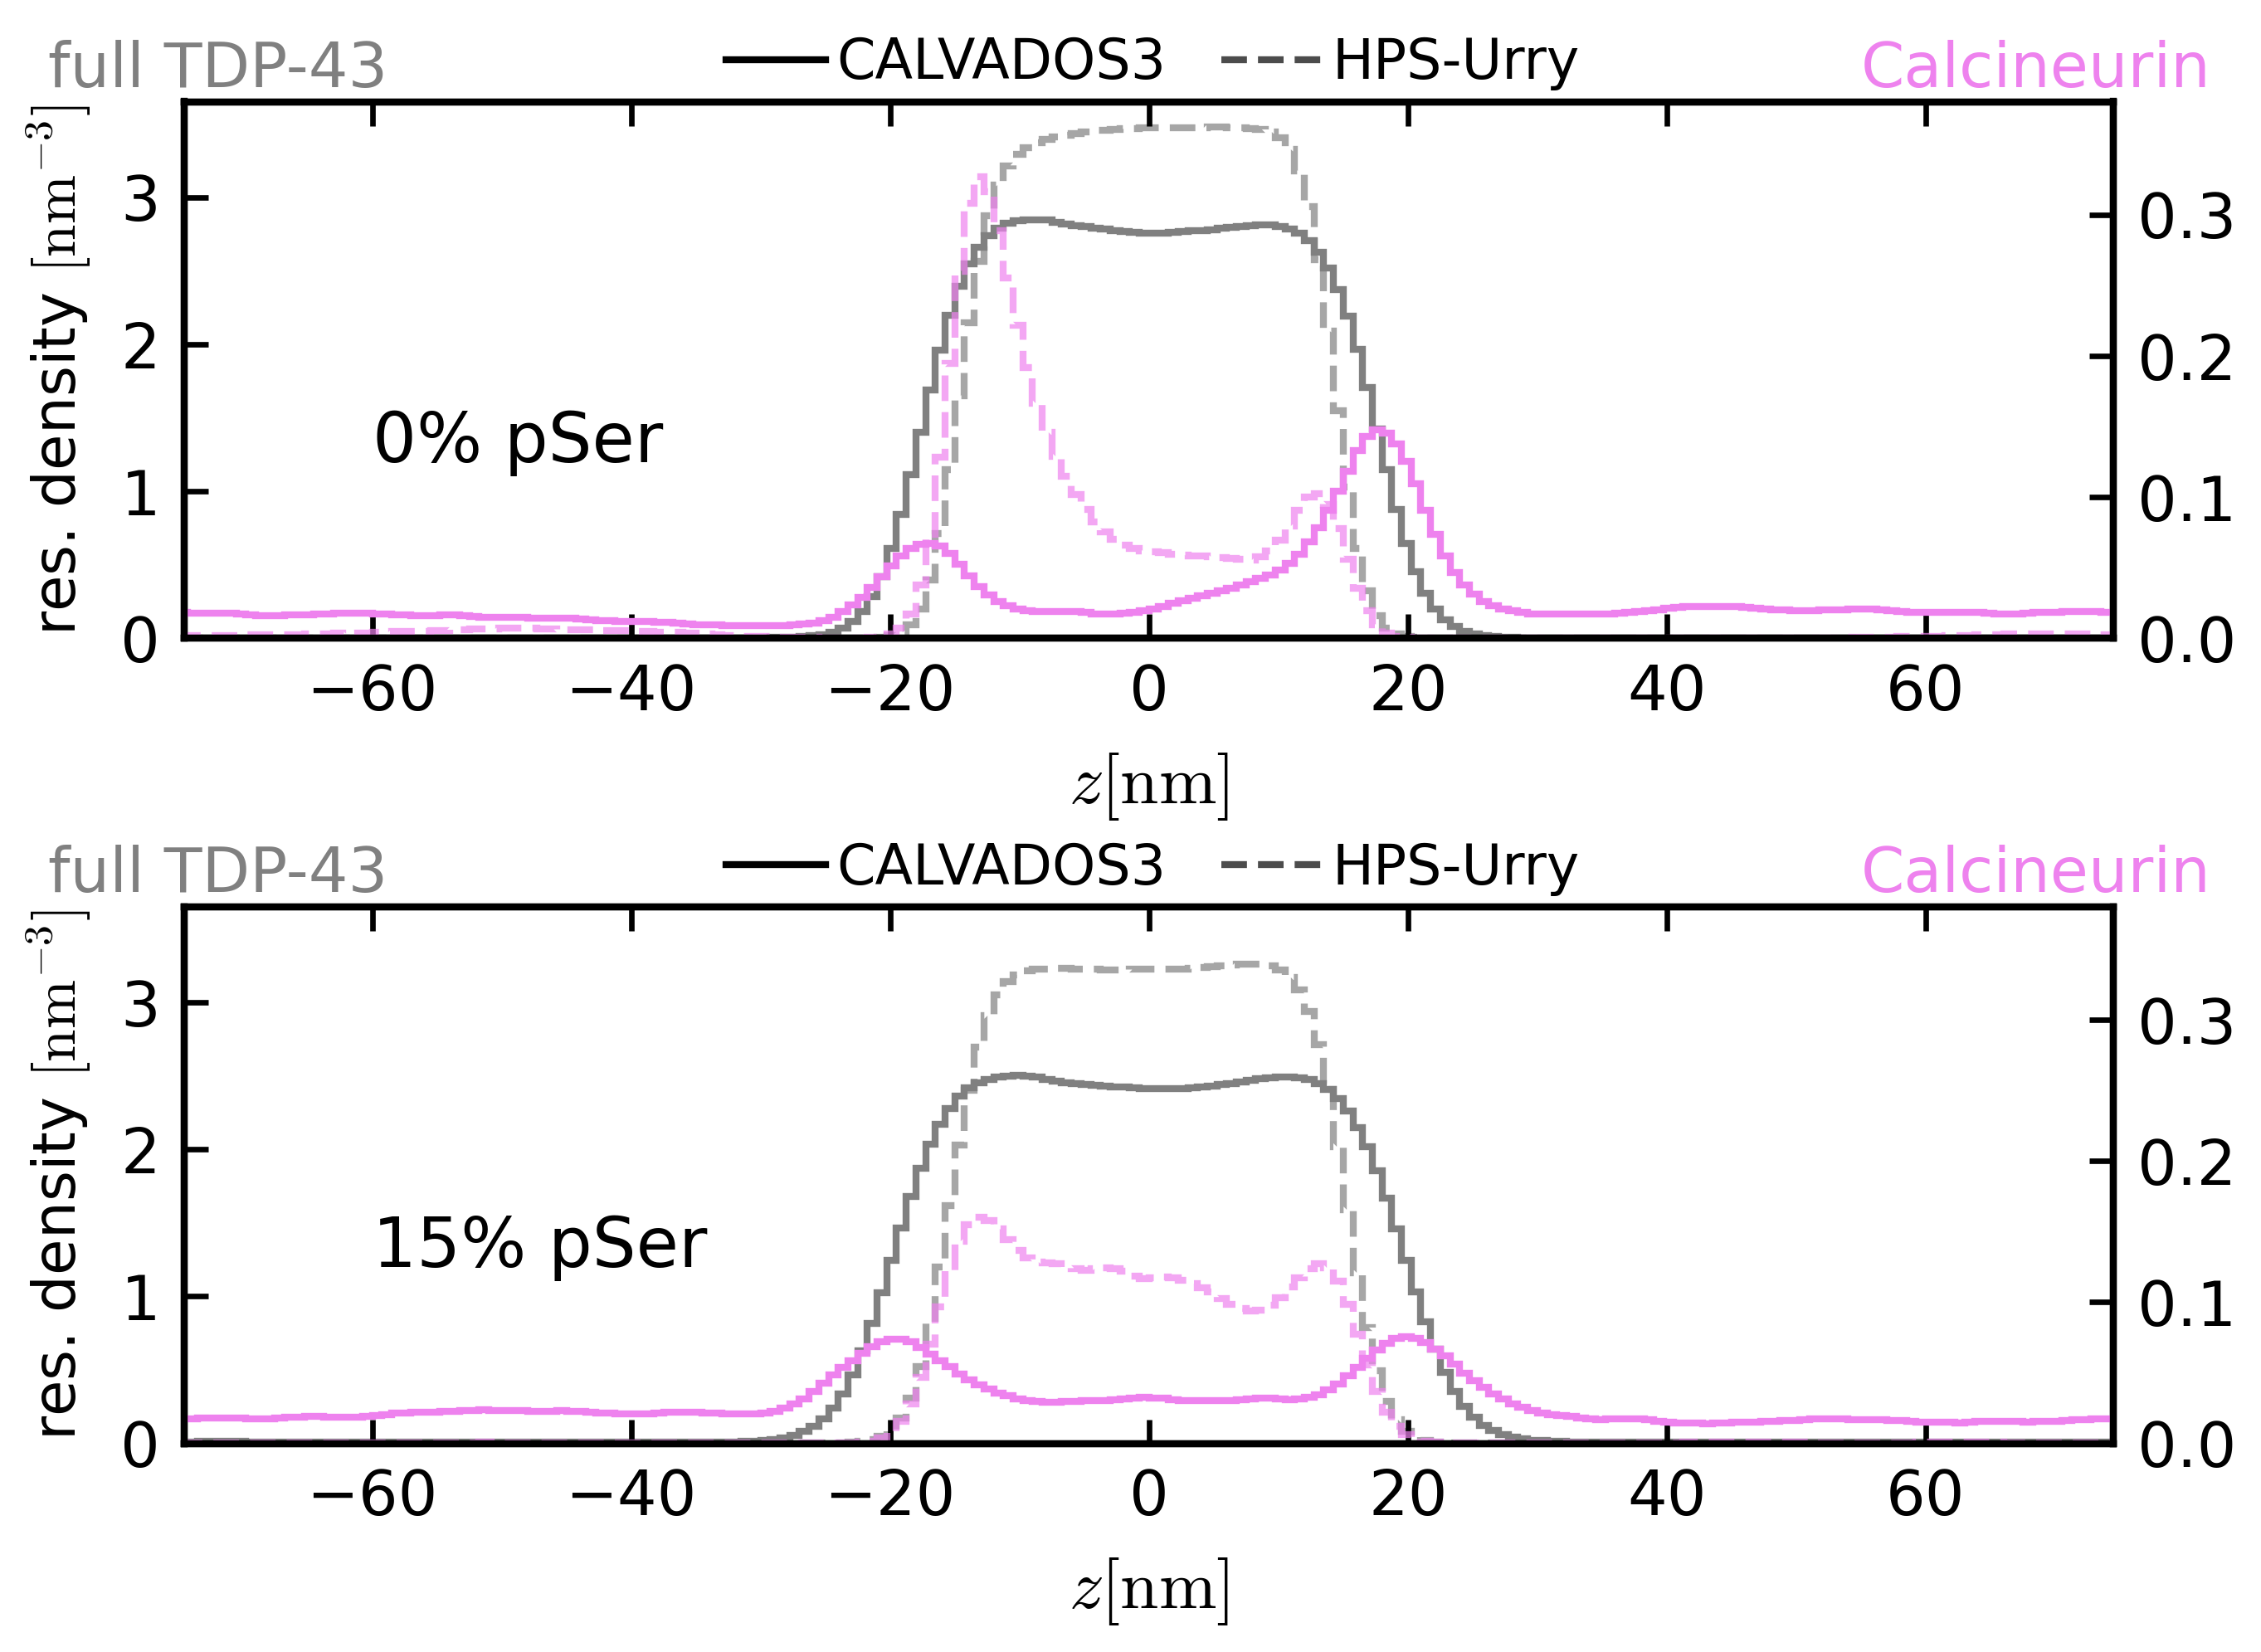

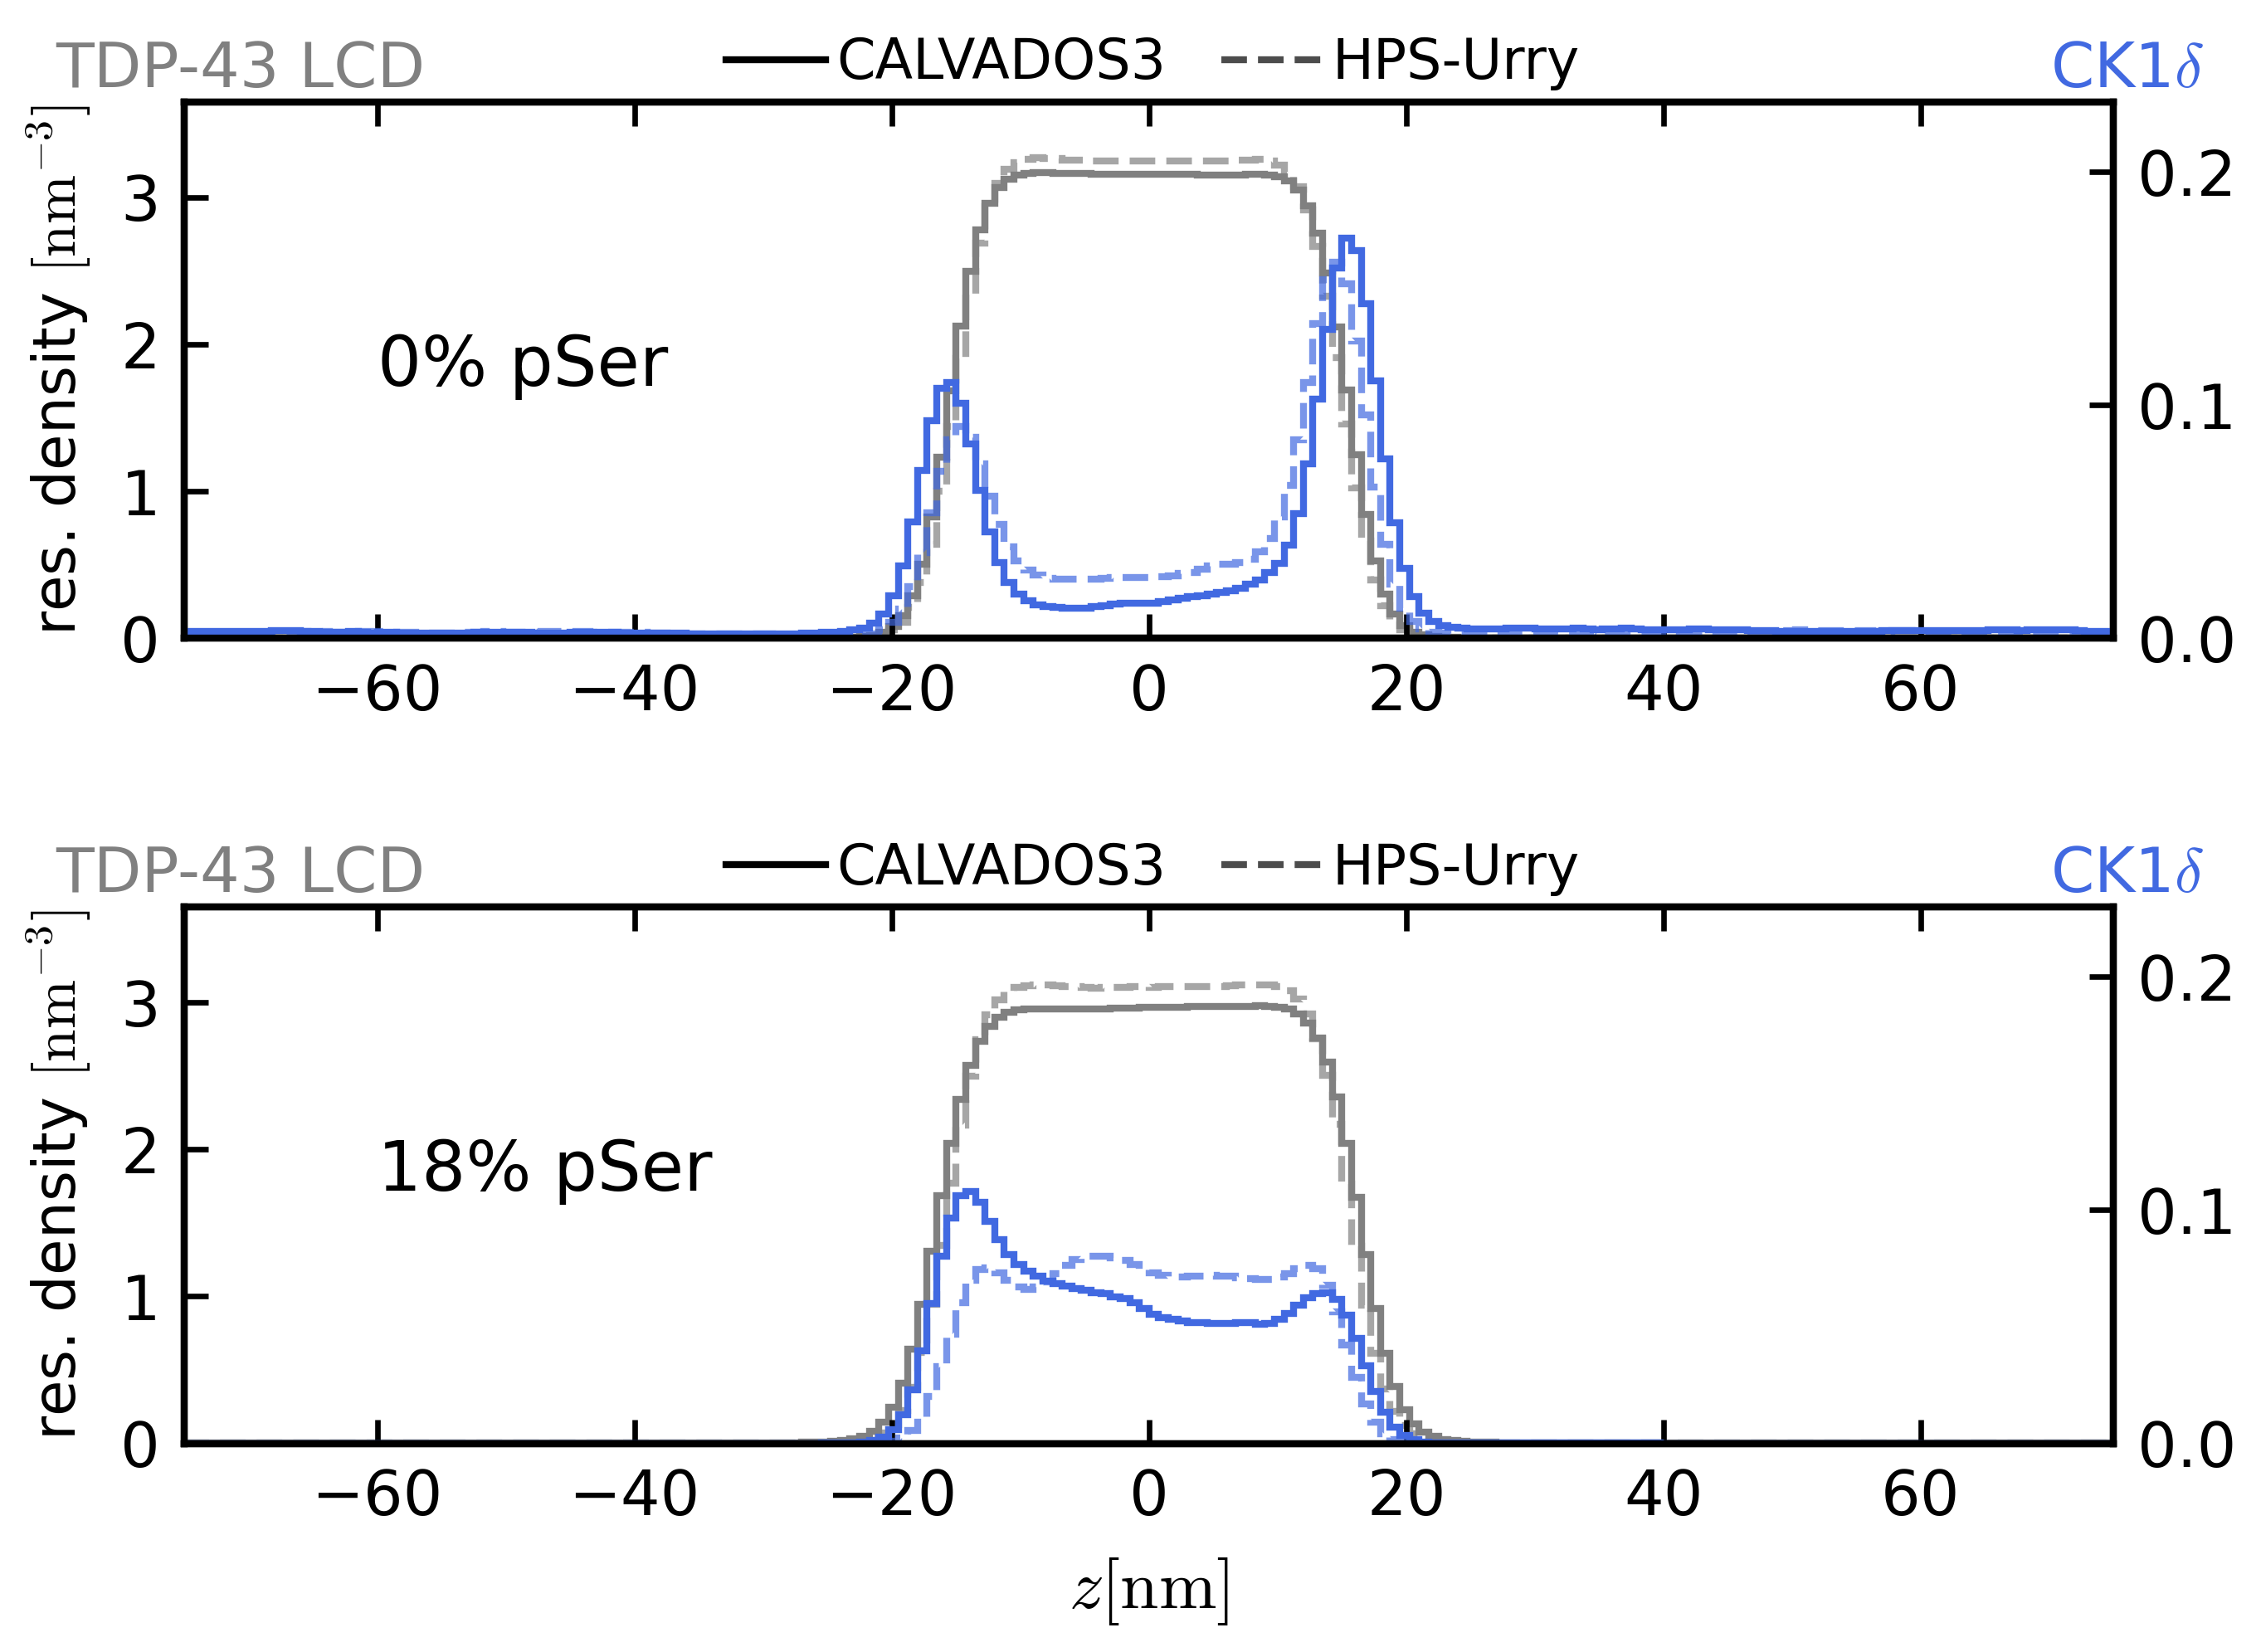

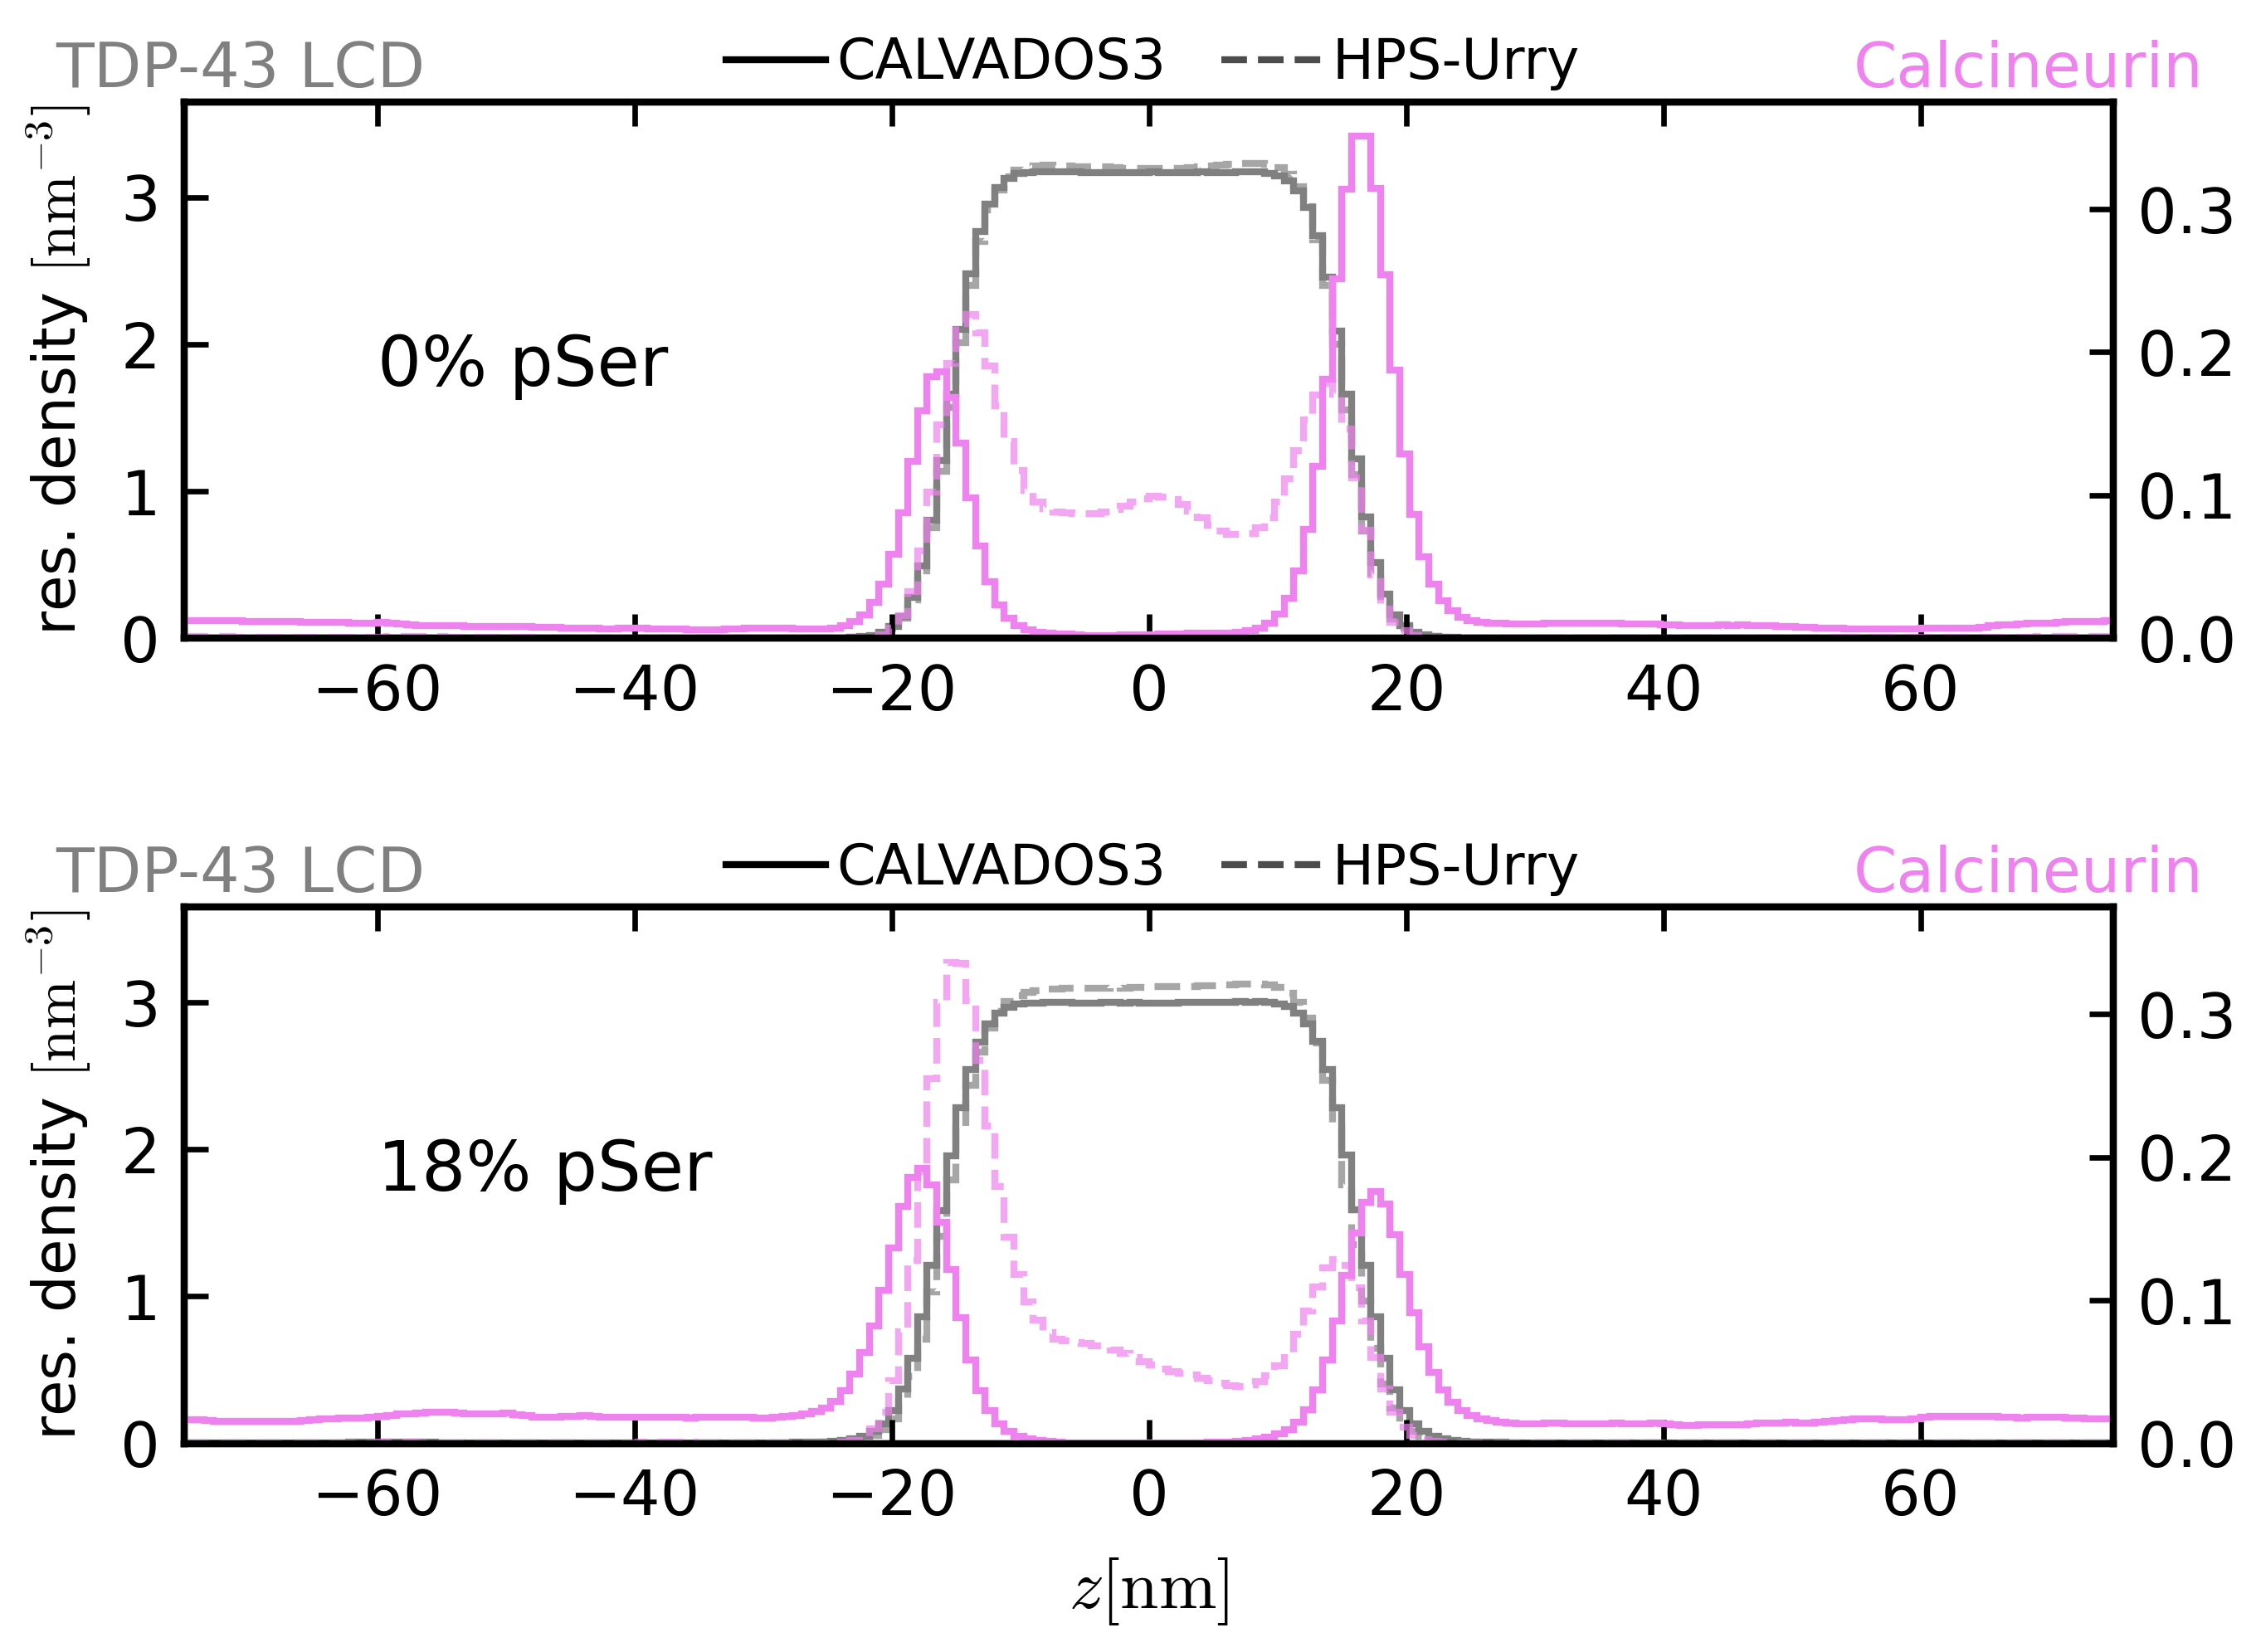

In [36]:
ENZ_STYLE = {'ck1d': (r'CK1$\delta$', 'royalblue'), 'pp3': ('Calcineurin', 'violet')}


def plot_slab_enzyme(system, enzyme, tdp_label, text_y, enz_ylim, xlim=75, xlabel_both=False):
    '''Two panels (0 pSer, with pSer): TDP-43 and enzyme profiles, CALVADOS3 vs HPS-Urry.'''
    n_tdp, npser = SLAB_SETS[system]
    files = [path_struct + slab_file(system, enzyme, 'CAL3', npser, r) for r in REPLICAS]   # same pSer in all replicas
    pct = pser_percent(next(f for f in files if os.path.exists(f.replace('_dump_centered.gsd', '_end.gsd'))), n_tdp)
    enz_label, color = ENZ_STYLE[enzyme]
    f, axes = plt.subplots(2, 1, figsize=(5, 3.5))
    plt.subplots_adjust(hspace=0.5)
    for ax, n in zip(axes, (0, npser)):
        axr = ax.twinx()
        for model, ls, alpha in (('CAL3', '-', 1.0), ('HPSu', '--', 0.7)):
            bins, tdp, bins_e, enz = slab[system, enzyme, model, n]
            ax.stairs(tdp, stairs_edges(bins), ls=ls, alpha=alpha, color='grey')
            axr.stairs(enz, stairs_edges(bins_e), ls=ls, alpha=alpha, color=color)
        ax.plot([], [], '-k', label='CALVADOS3')
        ax.plot([], [], '--k', label='HPS-Urry', alpha=0.7)
        ax.legend(loc=(0.275, 1), ncols=2, frameon=False)
        ax.set_ylabel(r'res. density $[\mathrm{nm}^{-3}]$', fontsize=8.5)
        if xlabel_both or ax is axes[1]:
            ax.set_xlabel(r'$z [\mathrm{nm}]$')
        ax.text(-85, 3.75, tdp_label, color='grey', fontsize=9)
        ax.text(82, 3.75, enz_label, color=color, fontsize=9, ha='right')
        ax.text(-60, text_y, f'{pct if n else 0:.0f}% pSer')
        ax.set_xlim(-xlim, xlim)
        ax.set_ylim(0, 3.65)
        axr.set_ylim(0, enz_ylim)


plot_slab_enzyme('150-full-tdp43', 'ck1d', 'full TDP-43', 1.2, 0.125, xlabel_both=True)
savefig(path_struct_pl + 'density_profile_150-full-tdp43_5-ck1d-open_HPSu')

plot_slab_enzyme('150-full-tdp43', 'pp3', 'full TDP-43', 1.2, 0.38, xlim=74.5, xlabel_both=True)
savefig(path_struct_pl + 'density_profile_150-full-tdp43_5-pp3_HPSu')

plot_slab_enzyme('400-tdp43-lcd', 'ck1d', 'TDP-43 LCD', 1.72, 0.23)
savefig(path_struct_pl + 'density_profile_400-tdp43-lcd_5-ck1d_HPSu')

plot_slab_enzyme('400-tdp43-lcd', 'pp3', 'TDP-43 LCD', 1.72, 0.375)
savefig(path_struct_pl + 'density_profile_400-tdp43-lcd_5-pp3_HPSu')

## TDP-43 species arrangement
### N-terminal domain vs LCD in full-length TDP-43

z_NT_CT_150-full-tdp43_5-pp3_CAL3: sim1 (4900 frames), sim2 (2400 frames)


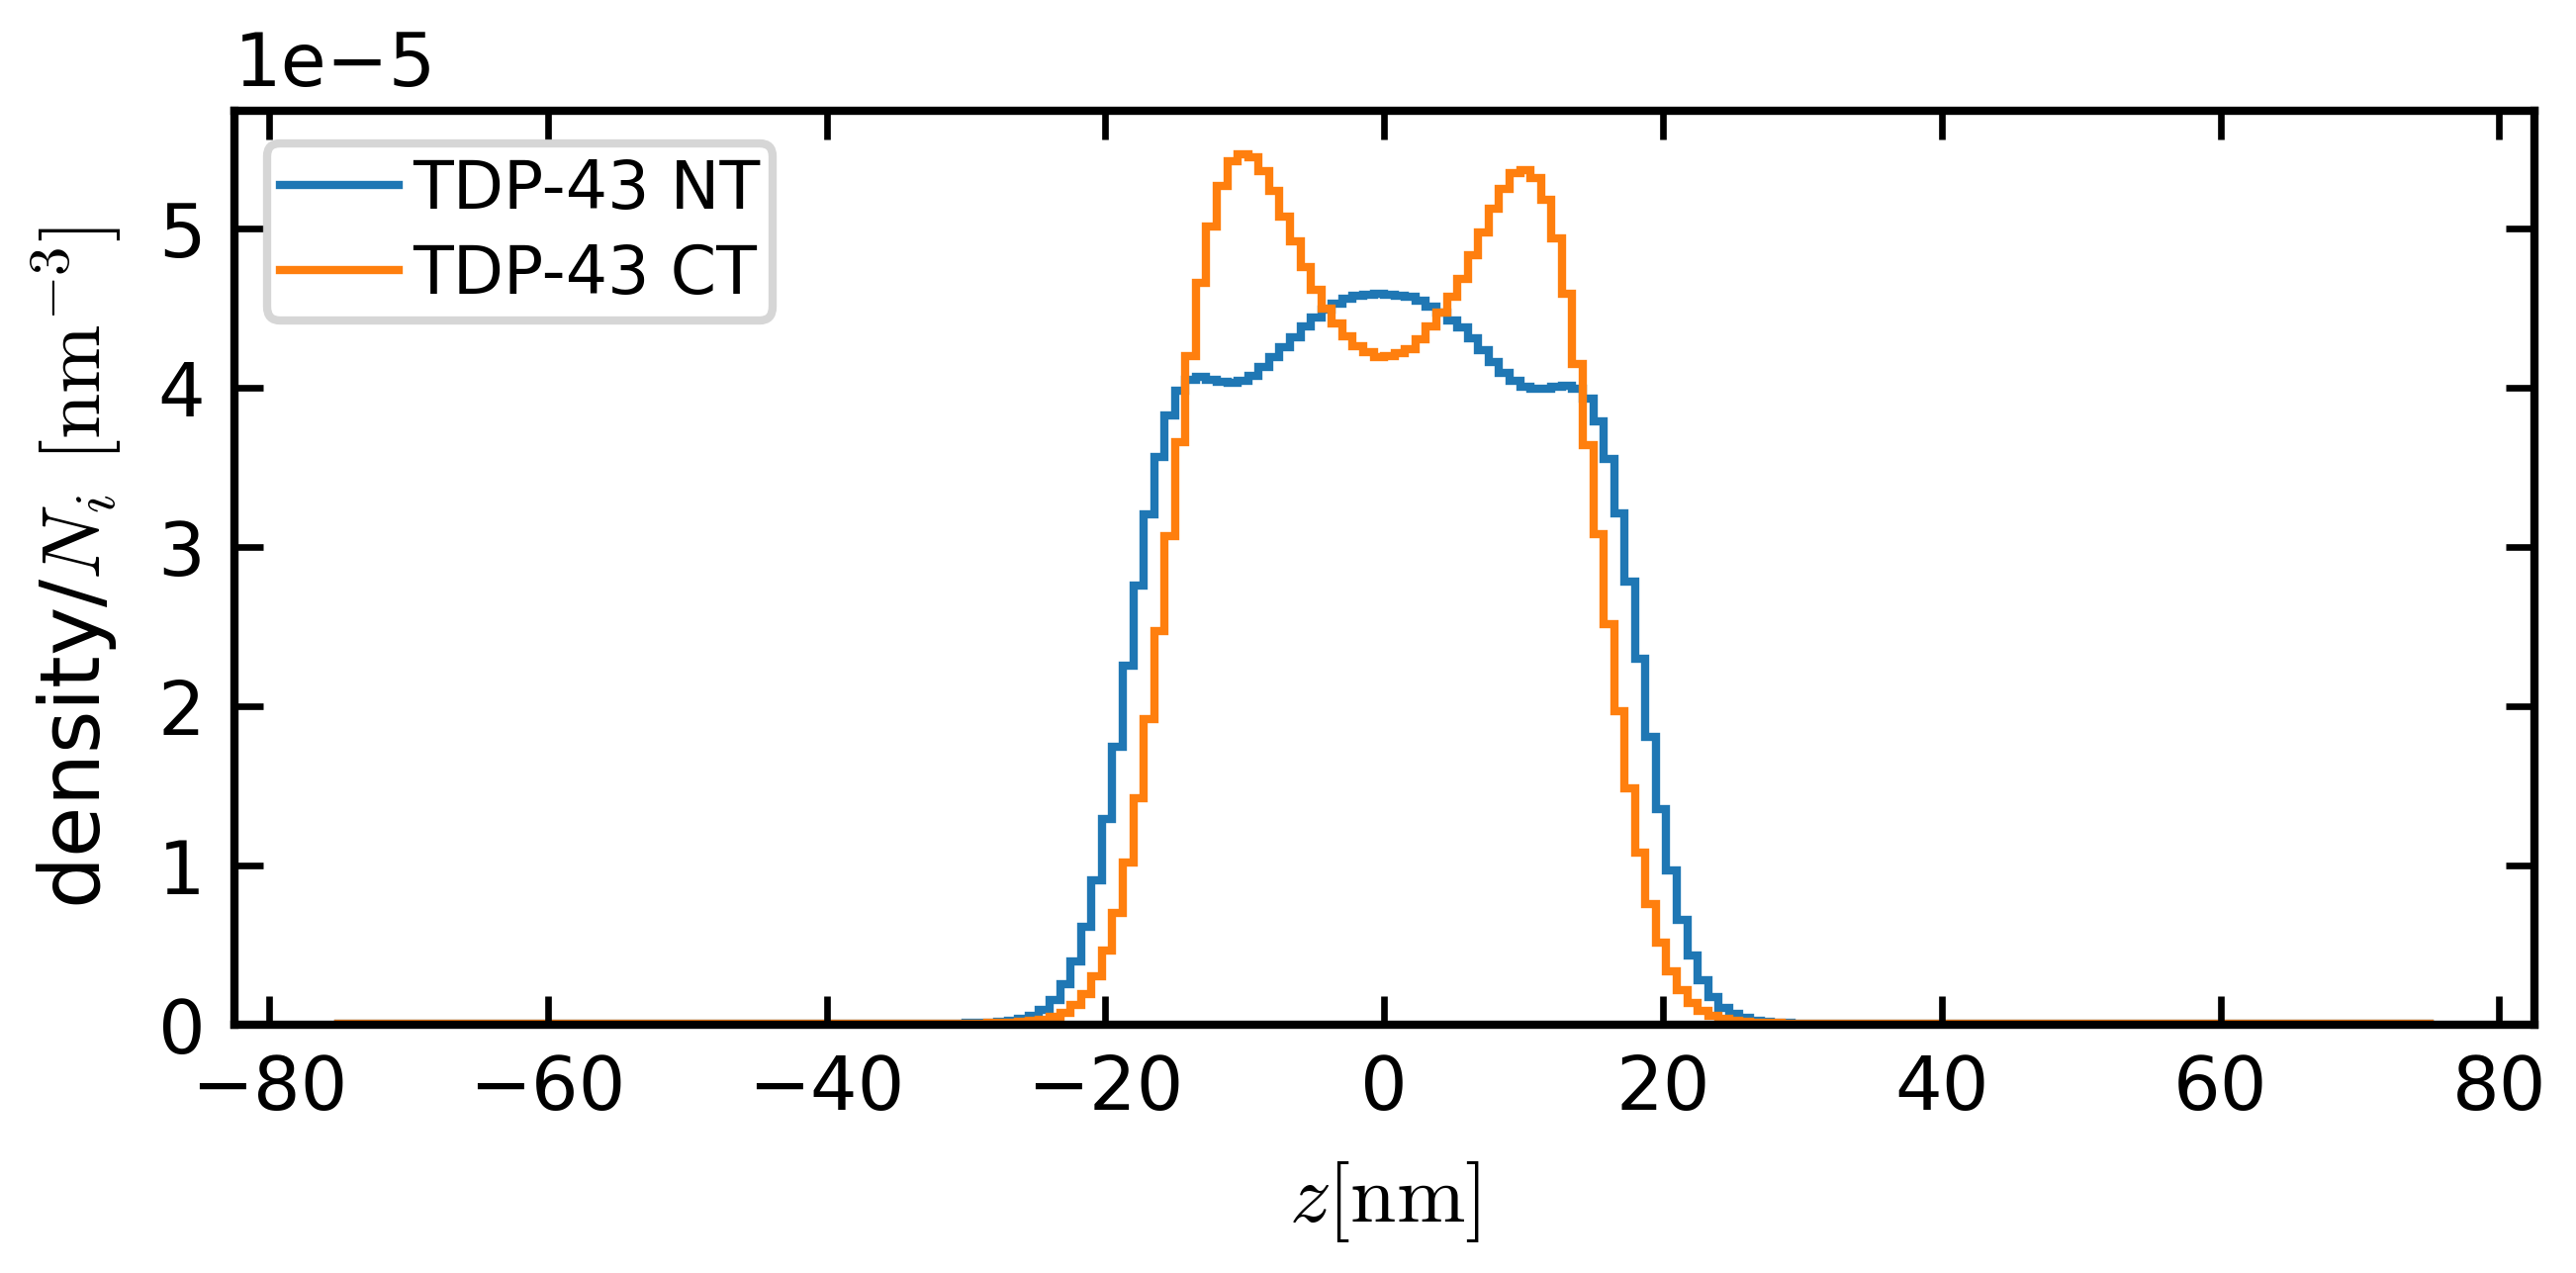

In [37]:
# full TDP-43: 150 chains of 414 beads, residues 0-259 NT, 260-413 CT (LCD)
N_FULL = 150
NT = [i + 414 * j for j in range(N_FULL) for i in range(260)]
CT = [i + 414 * j for j in range(N_FULL) for i in range(260, 414)]


def nt_ct_dump(r):
    return path_struct + f'sim_eq_slab_150-full-tdp43_5-pp3_CAL3_fr01/sim{r}_eq_slab_150-com-full-tdp43_5-com-pp3_CAL3_fr01_dump_centered.gsd'


def compute_nt_ct(f):
    b_nt, d_nt = hpap.compute_density_profile(f, axis=2, nbins=200, group=NT, therm=100)
    b_ct, d_ct = hpap.compute_density_profile(f, axis=2, nbins=200, group=CT, therm=100)
    return dict(bins_nt=b_nt, nt=d_nt, bins_ct=b_ct, ct=d_ct, frames_used=dump_frames(f) - 100)


p = replica_average('z_NT_CT_150-full-tdp43_5-pp3_CAL3', nt_ct_dump, compute_nt_ct, ('nt', 'ct'),
                    old_file=prof_dir + 'z_NT_CT_150-full-tdp43_5-pp3_CAL3.npz')
bin_centers_nt, density_nt, bin_centers_ct, density_ct = p['bins_nt'], p['nt'], p['bins_ct'], p['ct']

f, ax1 = plt.subplots(1, 1, figsize=(5, 2))
# density per chain and per residue of the segment
ax1.stairs(density_nt / N_FULL / 260, stairs_edges(bin_centers_nt), ls='-', color='tab:blue', label='TDP-43 NT')
ax1.stairs(density_ct / N_FULL / 154, stairs_edges(bin_centers_ct), color='tab:orange', label='TDP-43 CT')
ax1.legend(loc='upper left')
ax1.set_xlabel(r'$z [\mathrm{nm}]$')
ax1.set_ylabel(r'density/$N_i$ $[\mathrm{nm}^{-3}]$')
savefig(path_struct_pl + 'density_profile_NT_CT_150-full-tdp43')

### LCD slab by pSer per chain (fixed pSer pattern)

Computing density profiles: 100%|██████████████████████████████████| 2500/2500 [00:02<00:00, 911.72it/s]


z_by_npSer_400-tdp43-lcd-1715pser_5-pp3_CAL3: sim1 (2400 frames), sim2 (2400 frames)


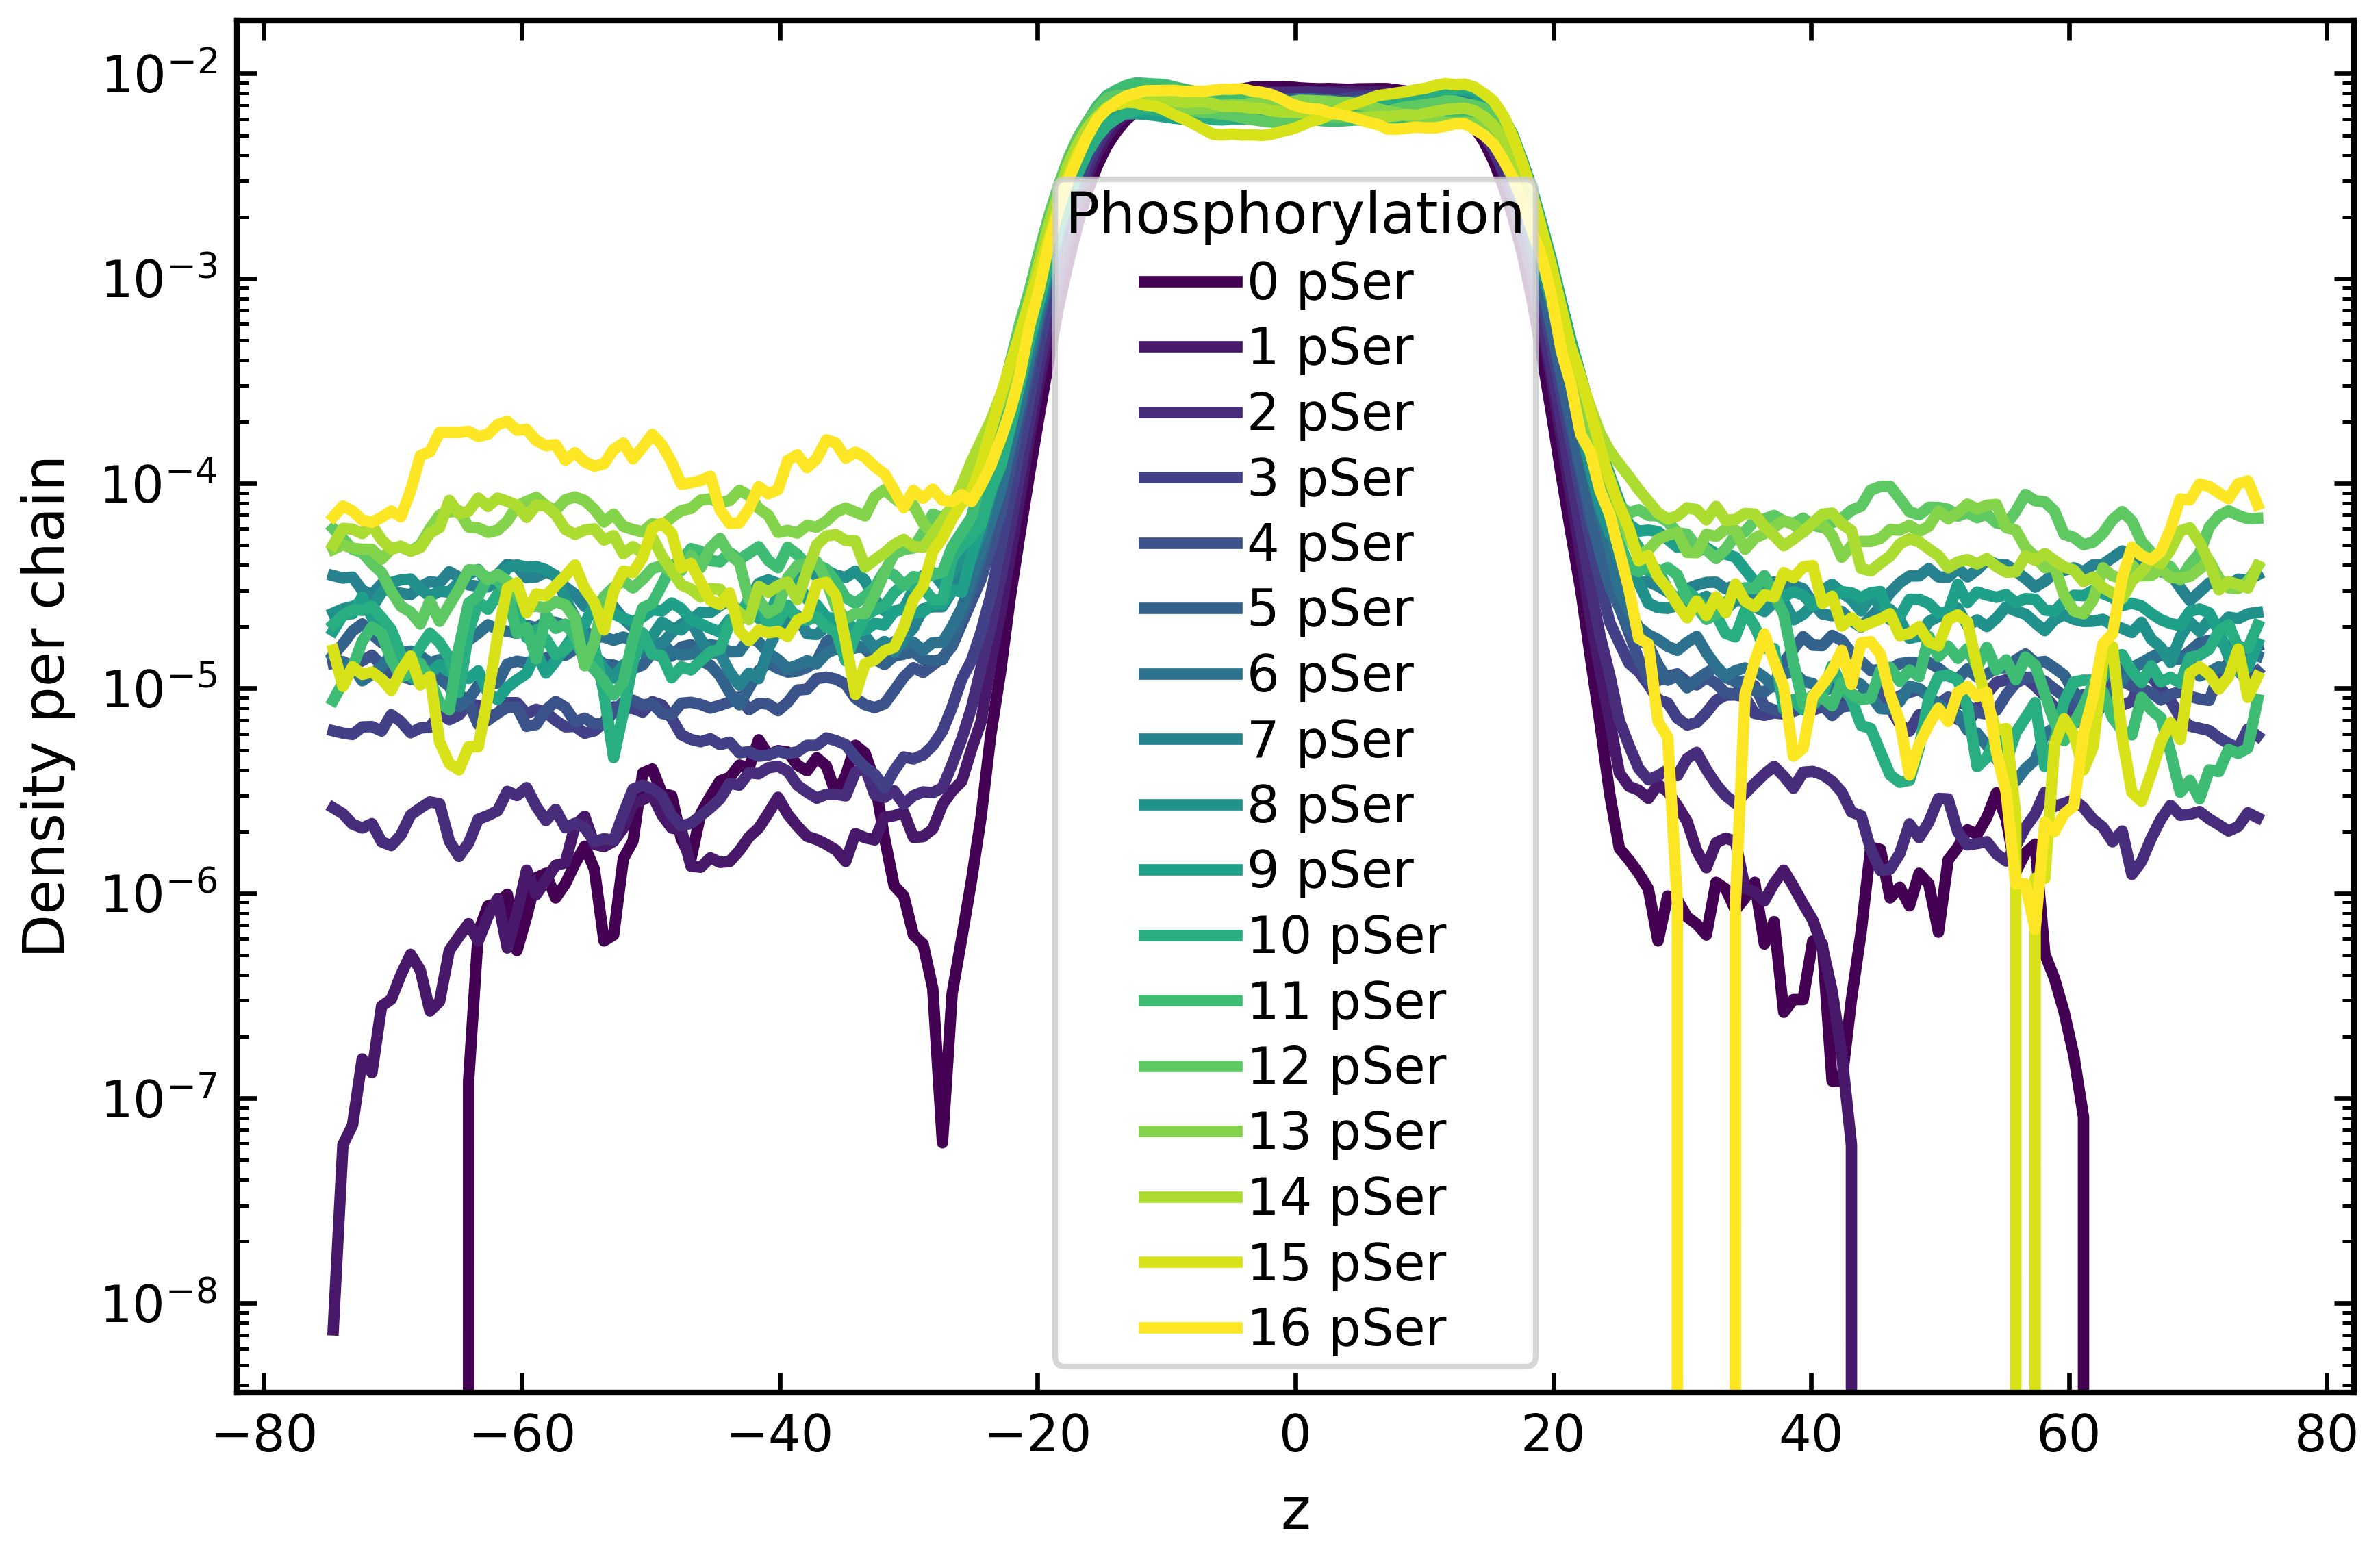

{'pSer 0–5': array([5.93002691e-06, 6.16070742e-06, 6.29450211e-06, 6.72664360e-06,
        6.62668205e-06, 6.02845060e-06, 5.93617839e-06, 5.68242983e-06,
        5.56247597e-06, 5.50403691e-06, 5.35793925e-06, 5.71164937e-06,
        5.11956940e-06, 4.57054979e-06, 4.78431373e-06, 4.74432910e-06,
        4.70742022e-06, 4.94117647e-06, 5.59938485e-06, 5.63629373e-06,
        5.32564398e-06, 5.29642445e-06, 5.45636294e-06, 5.62399077e-06,
        5.32871972e-06, 5.45174933e-06, 5.39792388e-06, 5.01806997e-06,
        4.95040369e-06, 5.36255286e-06, 5.72702807e-06, 6.06074587e-06,
        6.19915417e-06, 6.66051519e-06, 6.10073049e-06, 5.67781622e-06,
        5.66551326e-06, 5.51326413e-06, 5.22875817e-06, 5.24259900e-06,
        5.12110727e-06, 5.09650135e-06, 4.97808535e-06, 5.15186467e-06,
        5.62399077e-06, 5.82391388e-06, 5.79623222e-06, 5.68242983e-06,
        5.70242215e-06, 5.73010381e-06, 6.05151865e-06, 6.56824298e-06,
        6.53133410e-06, 6.19454056e-06, 6.17608612e-

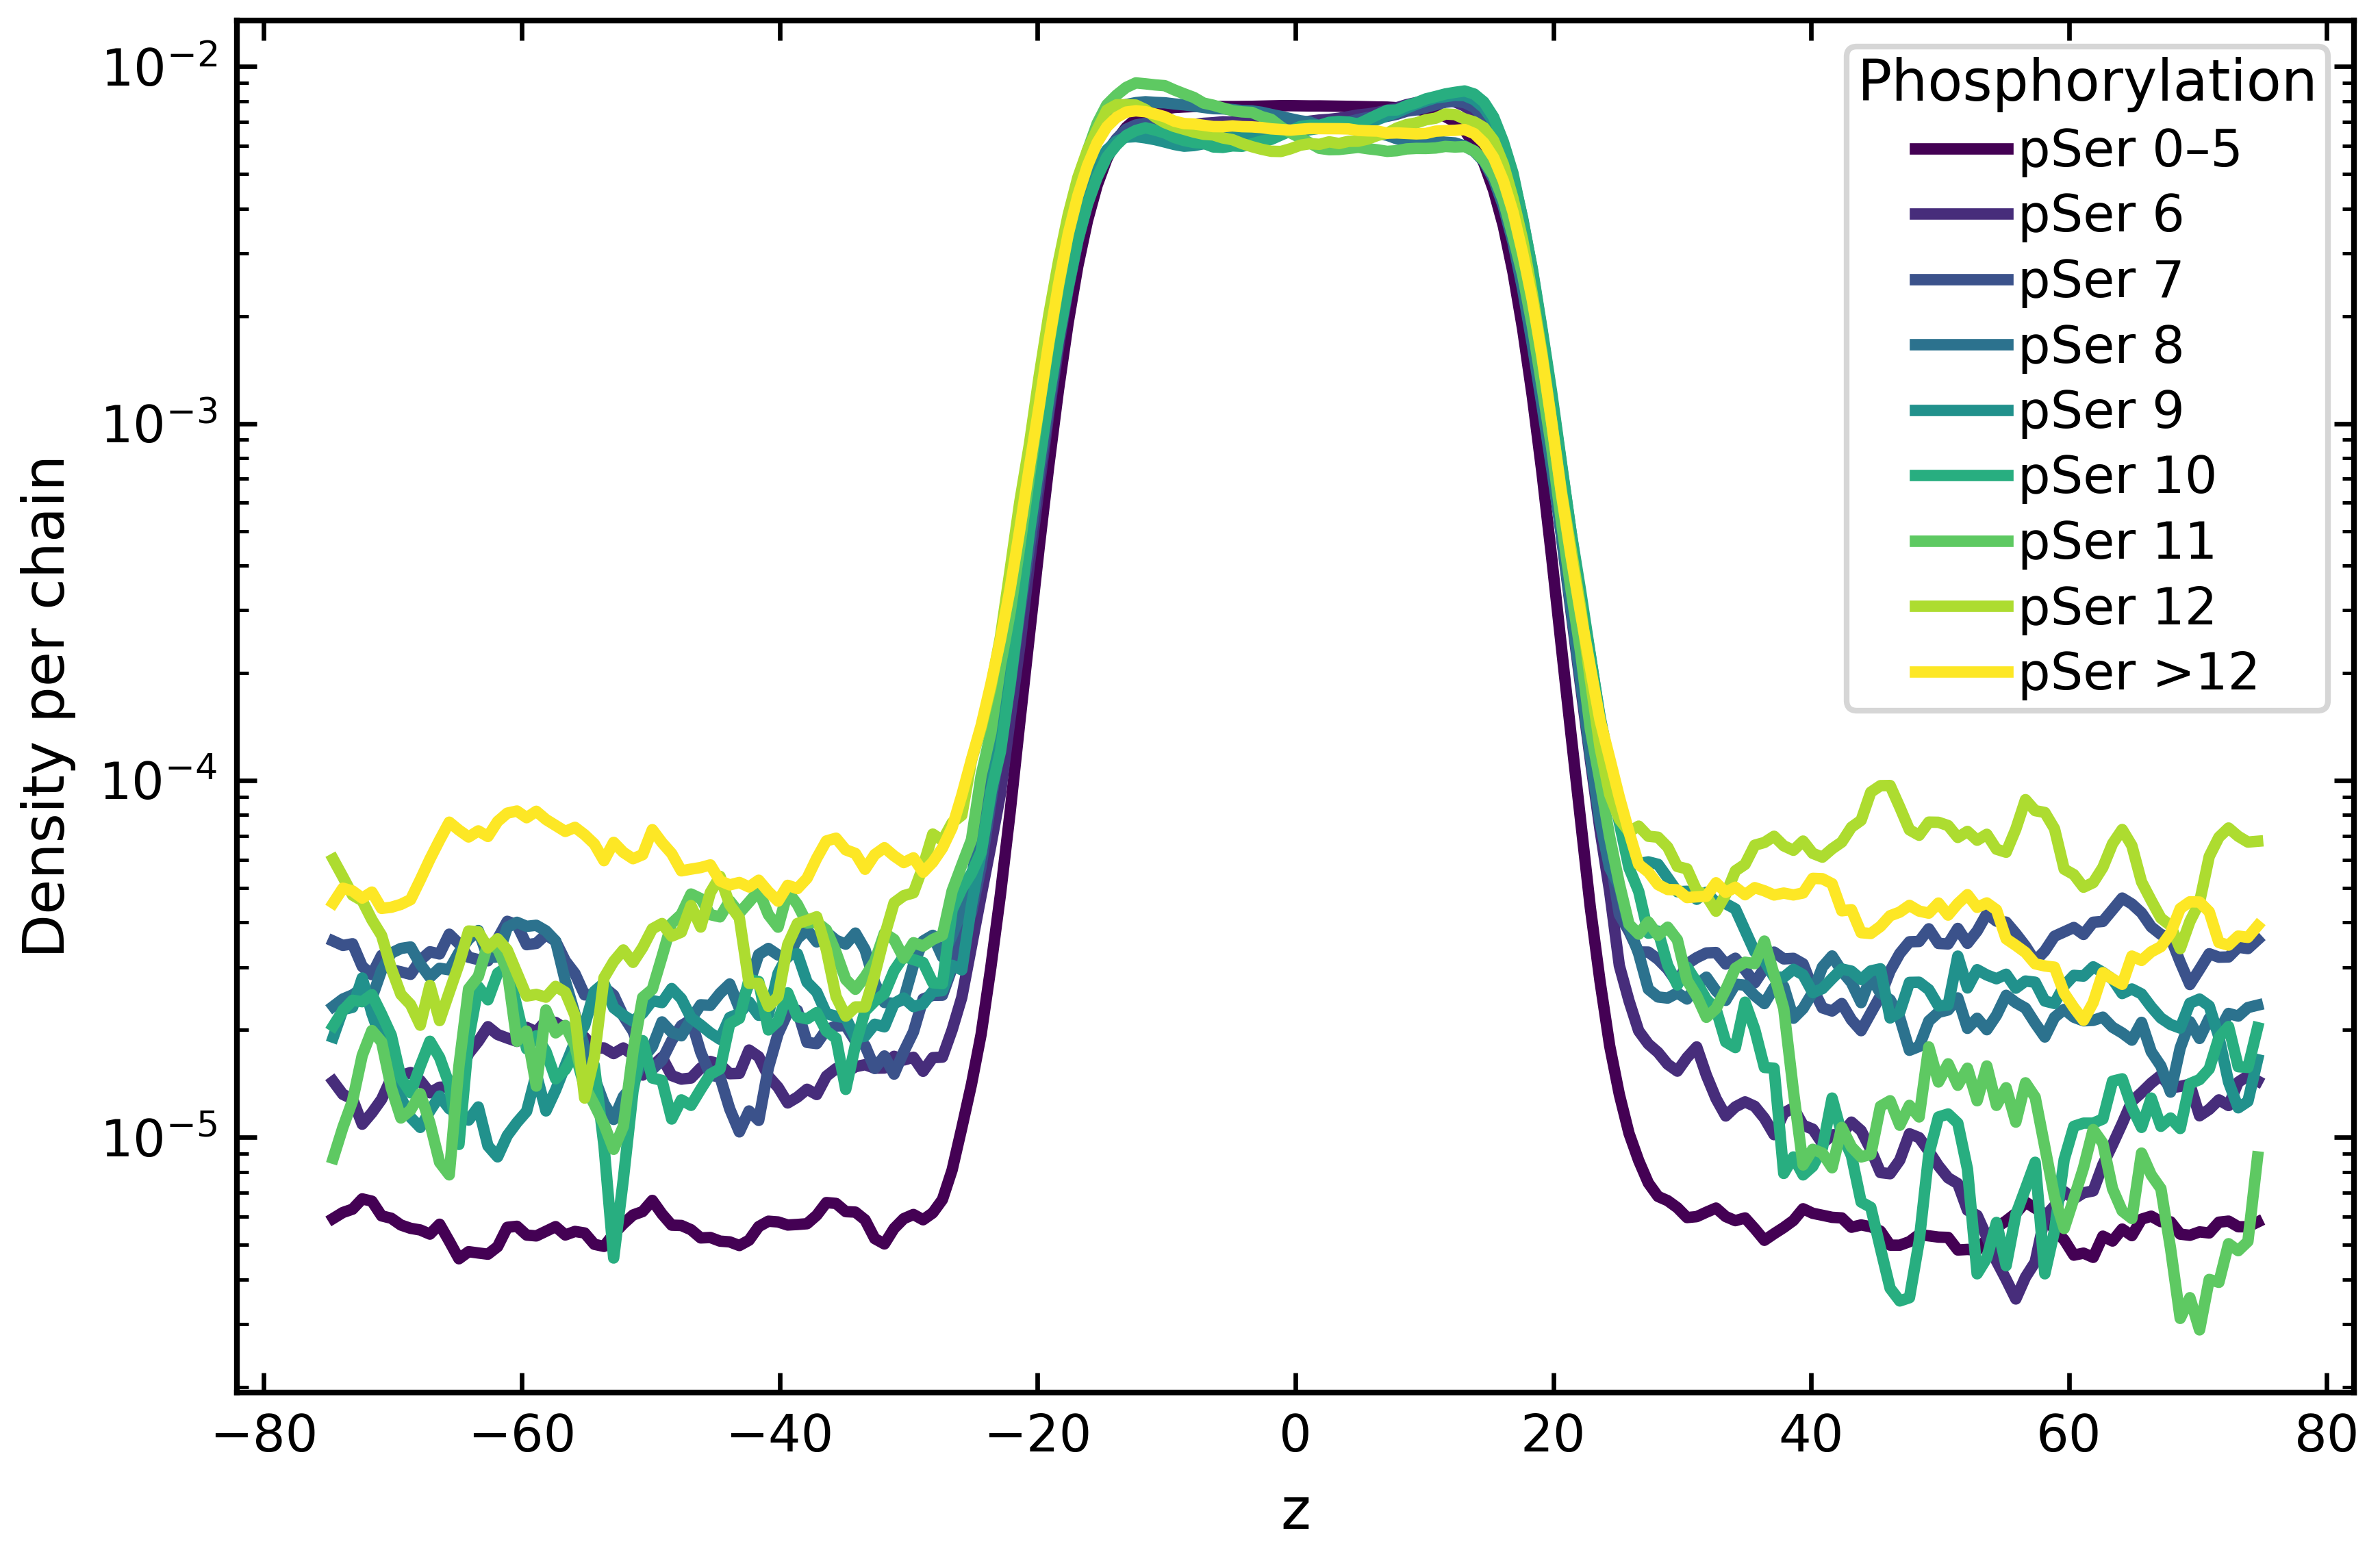

In [19]:
def npser_dump(r):
    return path_struct + f'sim_eq_slab_400-tdp43-lcd_5-pp3_CAL3_fr01/sim{r}_eq_slab_400-tdp43-lcd-1715pser_5-com-pp3_CAL3_fr01_dump_centered.gsd'


def compute_by_npser(f):
    # same pSer pattern in all replicas: same classes and chain counts
    bins, dens, counts = hpap.compute_density_profile_by_npSer(f, n_chains=400, beads_per_chain=N_LCD, axis=2, nbins=200,
                                                               therm=100)
    classes = np.array(sorted(dens))
    return dict(bins=bins, classes=classes, profiles=np.array([dens[c] for c in classes]),
                counts=np.array([counts[c] for c in classes]), frames_used=dump_frames(f) - 100)


p = replica_average('z_by_npSer_400-tdp43-lcd-1715pser_5-pp3_CAL3', npser_dump, compute_by_npser, ('profiles',),
                    old_file=prof_dir + 'z_by_npSer_400-tdp43-lcd-1715pser_5-pp3_CAL3.npz')
bin_centers = p['bins']
densities_by_pser = dict(zip(p['classes'].tolist(), p['profiles']))
chain_counts = dict(zip(p['classes'].tolist(), p['counts'].tolist()))

plot_radial_density_profiles_by_npSer(bin_centers, densities_by_pser, chain_counts, logscale=True, radial=False)

groups = {'pSer 0–5': lambda x: 0 <= x <= 5, **{f'pSer {n}': (lambda x, n=n: x == n) for n in range(6, 13)},
          'pSer >12': lambda x: x > 12}
plot_radial_density_profiles_by_npSer(bin_centers, densities_by_pser, chain_counts, logscale=True, radial=False, groups=groups,
                                      save=path_struct_pl + 'density_z_by_npSer_400-tdp43-lcd-1715pSer_slab_log')